<h1><bold>
Atelier 1: Systèmes de Recherche d'Images par le Contenu CBIR - Descripteurs globaux </bold>

----
<h2>1	Introduction</h2>

L’objectif de cet atelier est de vous initier aux systèmes de recherche basée sur le contenu visuel (CBIR, Content-Based Image Retrieval). Le CBIR permet de rechercher des images similaires à une image requête dans une base constituée d’images. Cette similarité n'est pas calculée sur les images elles-mêmes, mais par le biais d’une descripteur choisi par celui qui a conçu le système. La figure ci-dessous présente une vue globale d’un système CBIR.



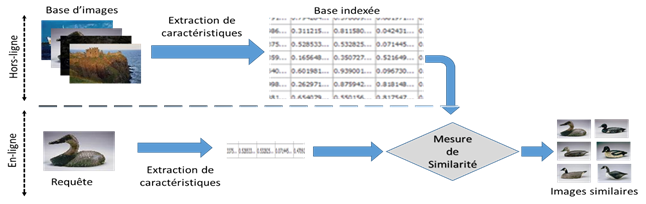

Un système CBIR est organisé en deux phases :


1.   Phase hors ligne, souvent appelée indexation, au cours de laquelle un vecteur descripteur est extrait pour chaque image et enregistré sous forme de base d'index.
2.   Phase en ligne, souvent appelée recherche, au cours de laquelle le système recherche les images similaires à une image requête. Le même type de descripteur est extrait de l'image requête et comparé à la base d'index.



Deux paramètres sont à prendre en considération lors de l’élaboration d’un système CBIR : les descripteurs (également appelés caractéristiques) à utiliser pour constituer la base d'index, et la mesure de similarité à utiliser pour rechercher les images les plus similaires à une image requête. Ainsi, la recherche se fait en mesurant la distance entre les descripteurs plutôt qu'entre les images.
<br>
<br>
Les descripteurs utilisés ici pour constituer la base d'index sont des descripteurs globaux de bas niveau, tels que : la forme, la couleur et la texture. La mesure de similarité utilisée peut être une simple distance euclidienne.

<h2>2	Base d’images</h2>
Pour cet atelier, nous allons utiliser une partie de la base d’images COREL. La base COREL contient 10 800 images classées en 80 groupes d’images. Cette base est parfaite pour comprendre les fondamentaux du CBIR. Ici, nous allons utiliser seulement 270 images appartenant à deux groupes d’images et qui sont regroupées dans un seul dossier.<br>
Le lien vers la base d'images est le suivant : https://drive.google.com/drive/folders/1_k42mYdBMdQVd8bx_A3c89mJxcTKELqT?usp=drive_link <br>
<br>
Téléchargez la base sur votre Google Drive.
Le chemin du dossier sur votre drive doit être:
"My Drive/CBIR_DataSet/obj_decoys/"

In [ ]:
#  0. Configuration de l'environnement
import os, glob, re, random, time
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from skimage.feature import graycomatrix, graycoprops, hog, local_binary_pattern

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Chemin attendu par l'énoncé : My Drive/CBIR_DataSet/{obj_decoys, img_requetes}
BASE_DIR = os.environ.get('CBIR_DIR', '/content/drive/MyDrive/CBIR_DataSet')

# Si le dossier n'est pas au bon endroit, on le cherche dans le Drive (3 niveaux max)
if not os.path.isdir(os.path.join(BASE_DIR, 'obj_decoys')):
    candidats = []
    for motif in ['/content/drive/MyDrive/obj_decoys', '/content/drive/MyDrive/*/obj_decoys',
                  '/content/drive/MyDrive/*/*/obj_decoys', '/content/*/obj_decoys']:
        candidats += glob.glob(motif)
    if candidats:
        BASE_DIR = os.path.dirname(candidats[0])
    else:
        raise FileNotFoundError("Dossier 'obj_decoys' introuvable : vérifie que CBIR_DataSet est bien dans ton Drive.")

DB_DIR = os.path.join(BASE_DIR, 'obj_decoys')
REQ_DIR = os.path.join(BASE_DIR, 'img_requetes')
print('Base   :', DB_DIR)
print('Requêtes:', REQ_DIR)
random.seed(0); np.random.seed(0)

Mounted at /content/drive
Base   : /content/drive/MyDrive/CBIR_DataSet/CBIR_DataSet/obj_decoys
Requêtes: /content/drive/MyDrive/CBIR_DataSet/CBIR_DataSet/img_requetes


<h2>3	Implémentation</h2>

Pour la première étape, qui est l'indexation, le premier code à écrire consiste à parcourir toutes les images de la base de données afin d'extraire de chacune un vecteur descripteur approprié.

<h2>3.1	Lecture des images</h2>
1. Lire toutes les images de la base et afficher 6 images aléatoirement.<br>
2. Lire les deux images requête  qui se trouvent dans le dossier My Drive/CBIR_DataSet/img_requetes/

In [ ]:
#  3.1 Lecture des images 
EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

def lire_image(chemin):
    """Lit une image et la retourne en RGB (OpenCV lit en BGR)."""
    img = cv2.imread(chemin)
    if img is None:
        raise ValueError(f'Image illisible : {chemin}')
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def lister_images(dossier):
    return sorted(p for p in glob.glob(os.path.join(dossier, '**', '*'), recursive=True)
                  if p.lower().endswith(EXT))

chemins_base = lister_images(DB_DIR)
IMAGES = {os.path.relpath(p, DB_DIR): lire_image(p) for p in chemins_base}   # nom -> image RGB
NOMS = list(IMAGES.keys())

chemins_req = lister_images(REQ_DIR)
REQUETES = {os.path.basename(p): lire_image(p) for p in chemins_req}

print(f'{len(IMAGES)} images dans la base, {len(REQUETES)} images requête : {list(REQUETES)}')
tailles = pd.Series([f'{im.shape[1]}x{im.shape[0]}' for im in IMAGES.values()]).value_counts()
print('Tailles (largeur x hauteur) :'); print(tailles.to_string())
print('Exemples de noms :', NOMS[:5], '...', NOMS[-5:])

270 images dans la base, 2 images requête : ['ImageRequete.jpg', 'ImageRequete2.jpg']
Tailles (largeur x hauteur) :
120x80    270
Exemples de noms : ['382001.jpg', '382002.jpg', '382006.jpg', '382007.jpg', '382012.jpg'] ... ['856084.jpg', '856085.jpg', '856088.jpg', '856091.jpg', '856098.jpg']


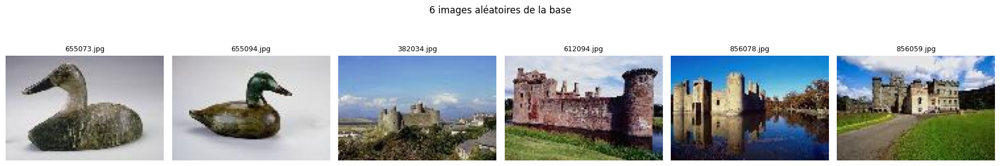

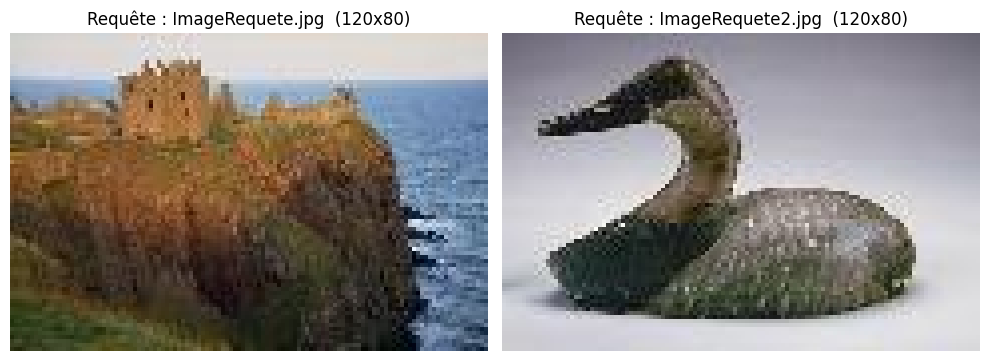

In [3]:
# Affichage de 6 images aléatoires de la base
fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
for ax, nom in zip(axes, random.sample(NOMS, 6)):
    ax.imshow(IMAGES[nom]); ax.set_title(nom, fontsize=9); ax.axis('off')
plt.suptitle('6 images aléatoires de la base'); plt.tight_layout(); plt.show()

# Affichage des images requête
fig, axes = plt.subplots(1, len(REQUETES), figsize=(5 * len(REQUETES), 4), squeeze=False)
for ax, (nom, im) in zip(axes[0], REQUETES.items()):
    ax.imshow(im); ax.set_title(f'Requête : {nom}  ({im.shape[1]}x{im.shape[0]})'); ax.axis('off')
plt.tight_layout(); plt.show()

In [4]:
# Fonctions d'affichage réutilisées dans tout le notebook
def afficher_resultats(img_req, resultats, titre='', k=5):
    """resultats : liste [(nom, distance), ...] triée par distance croissante."""
    fig, axes = plt.subplots(1, k + 1, figsize=(3 * (k + 1), 3.2))
    axes[0].imshow(img_req); axes[0].set_title('REQUÊTE', fontweight='bold', color='darkred')
    for ax, (nom, d) in zip(axes[1:], resultats[:k]):
        ax.imshow(IMAGES[nom]); ax.set_title(f'{nom}\nd={d:.4g}', fontsize=8)
    for ax in axes: ax.axis('off')
    if titre: plt.suptitle(titre, fontweight='bold')
    plt.tight_layout(); plt.show()

def comparer(img_req, dico_resultats, nom_req='', k=5):
    """Affiche une ligne de résultats par méthode pour comparer visuellement."""
    n = len(dico_resultats)
    fig, axes = plt.subplots(n, k + 1, figsize=(2.6 * (k + 1), 2.6 * n), squeeze=False)
    for i, (methode, res) in enumerate(dico_resultats.items()):
        axes[i, 0].imshow(img_req)
        axes[i, 0].set_title(methode, fontsize=9, fontweight='bold', color='darkred')
        for j, (nom, d) in enumerate(res[:k]):
            axes[i, j + 1].imshow(IMAGES[nom]); axes[i, j + 1].set_title(f'{nom}\nd={d:.3g}', fontsize=7)
    for ax in axes.ravel(): ax.axis('off')
    plt.suptitle(f'Requête {nom_req}', fontweight='bold'); plt.tight_layout(); plt.show()

<h2>3.2	Recherche par image entière</h2>
Pour une première implémentation d’un système CBIR, l’objectif est d’afficher les 5 images les plus similaires à l’image requête « ImageRequete.jpg » en se basant sur un calcul de différence entre images entières.<br>
<br>
1. Utiliser la distance enclidienne entre l'image requête et toutes les images de la base. Les distances seront enregistrées dans un dictionnaire et seront par la suite triées par ordre croissant.<br>
2. Afficher l'image requête ainsi que les 5 images les plus similaires en termes de distance euclidienne. Interpréter les résultats.

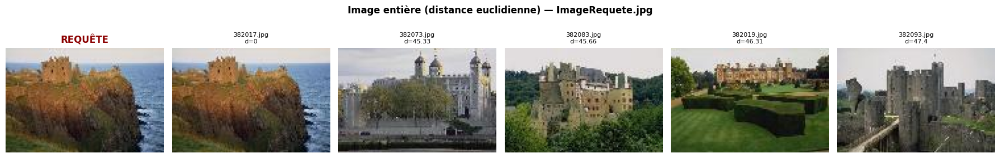

ImageRequete.jpg → top 5 : [('382017.jpg', 0.0), ('382073.jpg', 45.33), ('382083.jpg', 45.66), ('382019.jpg', 46.31), ('382093.jpg', 47.4)]


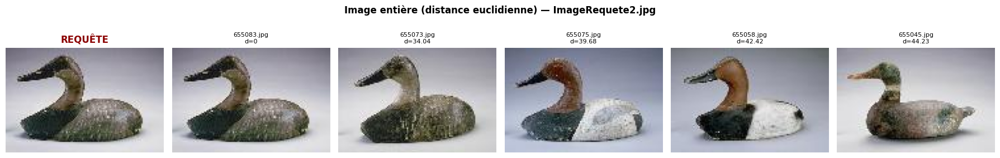

ImageRequete2.jpg → top 5 : [('655083.jpg', 0.0), ('655073.jpg', 34.04), ('655075.jpg', 39.68), ('655058.jpg', 42.42), ('655045.jpg', 44.23)]


In [5]:
# ============ 3.2 Recherche par image entière ============
# Les images n'ont pas toutes la même taille (paysage / portrait) : pour pouvoir les soustraire
# pixel à pixel, on les redimensionne toutes à une taille commune.
TAILLE_PIXELS = (128, 128)

def vecteur_pixels(img):
    return cv2.resize(img, TAILLE_PIXELS, interpolation=cv2.INTER_AREA).astype(np.float32).ravel() / 255.0

PIX_BASE = {nom: vecteur_pixels(im) for nom, im in IMAGES.items()}

def recherche_image_entiere(img_req):
    q = vecteur_pixels(img_req)
    distances = {nom: float(np.linalg.norm(q - v)) for nom, v in PIX_BASE.items()}   # dictionnaire
    return sorted(distances.items(), key=lambda x: x[1])                               # tri croissant

RES_PIXELS = {}
for nom_req, img_req in REQUETES.items():
    RES_PIXELS[nom_req] = recherche_image_entiere(img_req)
    afficher_resultats(img_req, RES_PIXELS[nom_req], f'Image entière (distance euclidienne) — {nom_req}')
    print(nom_req, '→ top 5 :', [(n, round(d, 2)) for n, d in RES_PIXELS[nom_req][:5]])

### Interprétation — recherche par image entière

- **Contrôle de cohérence :** les deux images requête font partie de la base (`382017.jpg` et `655083.jpg`). Elles sortent en premier avec une distance nulle, ce qui montre que l'indexation et la recherche fonctionnent.
- **Requête 1 (château sur falaise) :** les 4 résultats suivants sont des châteaux, tous de la même catégorie COREL (382). **Requête 2 (leurre de canard) :** les 4 résultats sont des leurres (catégorie 655), souvent dans la même posture (tête à gauche, corps allongé).
- **Pourquoi ça marche ici :** dans la base COREL, les photos d'une même catégorie ont une composition très régulière. Les leurres sont photographiés en studio sur un fond gris uniforme qui occupe la majorité des pixels, et les châteaux sont des paysages avec du ciel en haut et de la végétation en bas. La différence pixel à pixel capte surtout cette mise en page globale.
- **Limites :**
  - La distance compare chaque pixel à la même position. Un simple décalage, une rotation ou un changement de cadrage de l'objet fait exploser la distance, même si le contenu est identique.
  - Le « descripteur » est énorme (128×128×3 = 49 152 valeurs) et dépend de l'éclairage.
  - Il faut redimensionner toutes les images à une taille commune (ici les images font 120×80, ramenées à 128×128).

C'est pour ces raisons qu'on passe à des **descripteurs** compacts et plus invariants.

<h2>3.3	Recherche par Couleur</h2>
Dans cette partie, la caractéristique couleur sera utilisée pour développer notre système CBIR. La recherche est effectuée par similarité entre les caractéristiques de l’image requête et celles de la base d’index.  Le vecteur descripteur couleur à utiliser est constitué des valeurs des moments statistiques : moyenne et variance de chaque composante couleur. La taille du vecteur sera donc de 6.
<br>
<br>
Le code doit permettre d'abord d’indexer la base d’images et ensuite de lancer la recherche pour une image requête et d’afficher les 5 images les plus similaires.<br>
Le code contiendra 2 parties : <br>
1. La partie d'indexation : la fonction « CBIR_Indexation » est appelée avec comme paramètre la taille du vecteur descripteur. Cette partie ne doit être exécutée qu'une seule fois.<br>
2. La partie de recherche : la fonction « CBIR_Recherche » est appelée avec comme paramètres l'image requête, la matrice des descripteurs et les noms des images correspondantes.<br>
<br>
Le vecteur descripteur est créé par la fonction « getFeatures », qui prend en argument l'image et la taille du vecteur. C'est cette fonction que nous allons modifier pour ajouter d'autres descripteurs par la suite. Cette fonction appelle ici la fonction « color_Moments » qui retourne les 6 moments de couleur.


In [ ]:
#  3.3 Recherche par couleur (moments statistiques)
def color_Moments(img):
    """6 moments : moyenne et variance de chaque composante R, G, B (valeurs ramenées dans [0,1])."""
    x = img.reshape(-1, 3).astype(np.float64) / 255.0
    return np.concatenate([x.mean(axis=0), x.var(axis=0)])

# Registre des descripteurs : getFeatures concatène ceux de la liste DESCRIPTEURS_ACTIFS
DESCRIPTEURS = {'couleur': color_Moments}
DESCRIPTEURS_ACTIFS = ['couleur']

def getFeatures(img, fsize):
    v = np.concatenate([DESCRIPTEURS[d](img) for d in DESCRIPTEURS_ACTIFS]).astype(np.float64)
    assert v.size == fsize, f'fsize={fsize} mais le vecteur fait {v.size} ({DESCRIPTEURS_ACTIFS})'
    return v

def taille_vecteur():
    """Taille du vecteur pour les descripteurs actifs (calculée sur une image de la base)."""
    img = IMAGES[NOMS[0]]
    return sum(DESCRIPTEURS[d](img).size for d in DESCRIPTEURS_ACTIFS)

def CBIR_Indexation(fsize):
    """Phase hors ligne : un vecteur descripteur par image -> matrice d'index (N x fsize)."""
    t0 = time.time()
    ind_Matrix = np.zeros((len(NOMS), fsize))
    for i, nom in enumerate(NOMS):
        ind_Matrix[i] = getFeatures(IMAGES[nom], fsize)
    print(f'Indexation {DESCRIPTEURS_ACTIFS} : {ind_Matrix.shape} en {time.time()-t0:.1f}s')
    return ind_Matrix, list(NOMS)

def CBIR_Recherche(Imreq, ind_Matrix, noms):
    """Phase en ligne : distance euclidienne entre le descripteur de la requête et la base."""
    q = getFeatures(Imreq, ind_Matrix.shape[1])
    d = np.linalg.norm(ind_Matrix - q, axis=1)
    distances = dict(zip(noms, d))
    return sorted(distances.items(), key=lambda x: x[1])

Indexation ['couleur'] : (270, 6) en 0.3s


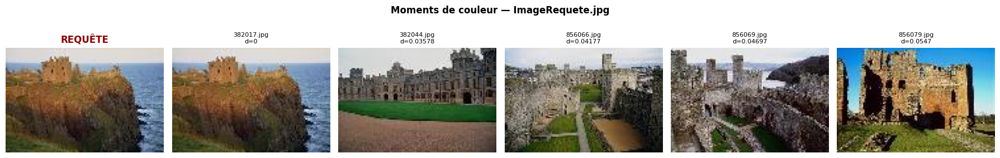

Descripteur requête : [0.4457 0.4074 0.3601 0.0529 0.0558 0.0816]


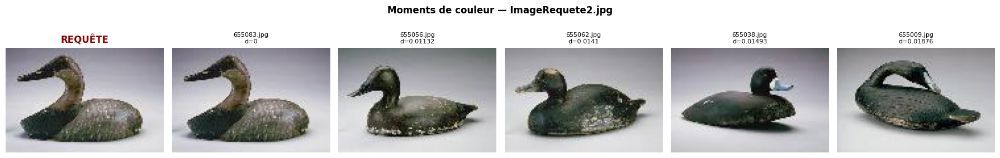

Descripteur requête : [0.5821 0.5768 0.5856 0.0554 0.0539 0.0655]


In [7]:
DESCRIPTEURS_ACTIFS = ['couleur']
fsize = taille_vecteur()                       # = 6
ind_couleur, noms = CBIR_Indexation(fsize)     # à n'exécuter qu'une fois

RES = {nom_req: {} for nom_req in REQUETES}   # on garde tous les résultats pour les comparaisons
for nom_req, img_req in REQUETES.items():
    RES[nom_req]['Couleur (6)'] = CBIR_Recherche(img_req, ind_couleur, noms)
    afficher_resultats(img_req, RES[nom_req]['Couleur (6)'], f'Moments de couleur — {nom_req}')
    print('Descripteur requête :', np.round(getFeatures(img_req, fsize), 4))

Afficher l'image requéte ainsi que les 5 images les plus similaires en termes de moments de couleur. Interpréter les résultats

### Interprétation — moments de couleur (6 valeurs)

- **Requête 2 (leurre) :** les 4 résultats sont des leurres de couleur sombre (vert foncé, noir) sur fond gris. Le vecteur de la requête (moyennes ≈ 0,58 sur R, G et B, presque égales) traduit bien une image dominée par un fond gris neutre, et les leurres de la base ont tous ce fond.
- **Requête 1 (château) :** les 4 résultats sont des châteaux, mais de catégories COREL différentes (382 et 856). Les moments décrivent l'**ambiance colorimétrique globale** (pierre, herbe, ciel) et non l'objet : un paysage quelconque aux mêmes teintes serait retrouvé de la même façon.
- **Avantages :**
  - Le descripteur est extrêmement compact (6 valeurs) : l'indexation des 270 images prend 0,3 s.
  - Il est invariant à la position des pixels, donc à la rotation de 90° et au miroir (voir 3.7).
- **Limites :**
  - Aucune information spatiale ni de forme.
  - Deux valeurs par canal (moyenne, variance) résument très grossièrement la distribution des couleurs.
  - Les distances sont très petites et proches les unes des autres (0,036 à 0,055), donc le classement est peu discriminant.

<h2>3.4	Recherche par Histogramme</h2>
"L’histogramme est souvent utilisé pour regrouper le nombre de pixels par intensité. L’histogramme peut être élaboré dans n’importe quel espace couleur : RGB, HSV, … et même en niveaux de gris. Des études ont montré que l’espace de couleur HSV est le plus adapté à ce type de système de recherche. L’histogramme est un vecteur dont la taille est égale au nombre de valeurs d’intensité dans l’image. Pour l’utiliser comme vecteur descripteur, l’idée est de quantifier l’histogramme en un nombre limité de caractéristiques afin de réduire la taille du descripteur.<br>
<br>
1. Modifier le code pour permettre d’avoir un système CBIR utilisant un vecteur descripteur composé des caractéristiques de couleur et d’histogramme. Il faut écrire une fonction « hsvHistogramFeatures » qui prend comme argument une image et qui retourne le vecteur descripteur créé à partir de l’histogramme. La fonction « getFeatures » doit être modifiée pour concaténer les deux vecteurs descripteurs de moments et d’histogramme.<br>
2. Relancer l'indexation avec en plus des moments de couleur, le descripteur à base d'histogramme. Lancer la recherche par le nouveau descripteur. Comparer les résultats de cette recherche avec la recherche utilisant seulement la caractéristique couleur.




Indexation ['couleur', 'histogramme'] : (270, 78) en 0.3s


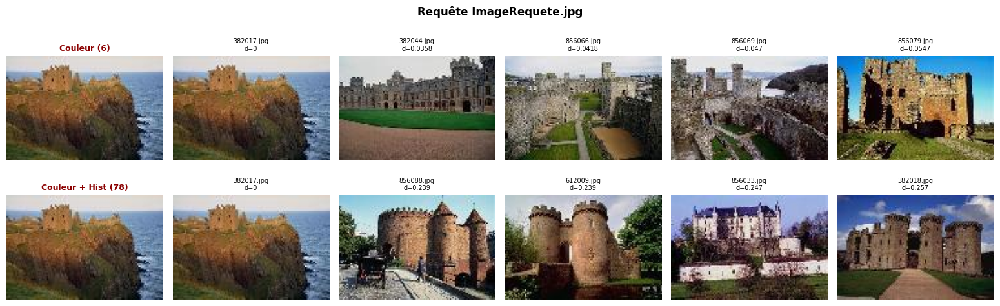

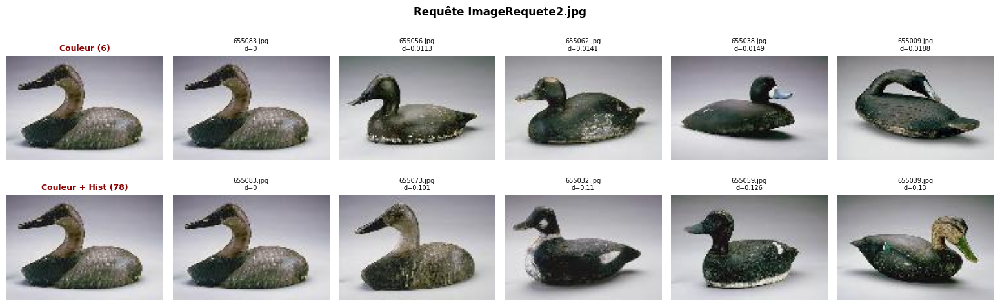

In [ ]:
#  3.4 Recherche par histogramme HSV
BINS_HSV = (8, 3, 3)   # quantification : 8 teintes x 3 saturations x 3 valeurs = 72 cases

def hsvHistogramFeatures(img, bins=BINS_HSV):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)            # OpenCV : H dans [0,180), S et V dans [0,256)
    h = cv2.calcHist([hsv], [0, 1, 2], None, list(bins), [0, 180, 0, 256, 0, 256]).ravel()
    return h / h.sum()                                    # normalisation : indépendant de la taille de l'image

DESCRIPTEURS['histogramme'] = hsvHistogramFeatures
DESCRIPTEURS_ACTIFS = ['couleur', 'histogramme']
fsize = taille_vecteur()                                  # = 6 + 72 = 78
ind_coul_hist, noms = CBIR_Indexation(fsize)

for nom_req, img_req in REQUETES.items():
    RES[nom_req]['Couleur + Hist (78)'] = CBIR_Recherche(img_req, ind_coul_hist, noms)
    comparer(img_req, {k: RES[nom_req][k] for k in ['Couleur (6)', 'Couleur + Hist (78)']}, nom_req)

### Interprétation — moments de couleur + histogramme HSV (6 + 72 valeurs)

- **Requête 1 :** les résultats changent. On obtient des châteaux aux tons brique/ocre avec du ciel bleu (`856088`, `612009`, `856033`, `382018`), visuellement plus proches des teintes chaudes de la falaise que les châteaux gris retournés par les moments seuls.
- **Requête 2 :** toujours 5 leurres, avec des plumages plus variés (blanc, vert), mais toujours sur fond gris.
- **Ce que l'histogramme apporte :** il décrit la **répartition complète** des couleurs, et non plus seulement leur moyenne et leur variance. L'espace **HSV** sépare la teinte (H) de la saturation et de la luminosité (S, V), ce qui le rend moins sensible à l'éclairage que RGB. La quantification 8×3×3 donne une teinte assez fine et une luminosité grossière.
- **Échelles compatibles :** l'histogramme est normalisé (somme = 1) et les moments sont dans [0, 1]. Les deux blocs contribuent donc tous les deux à la distance euclidienne.
- **Sur toute la base (section 4.6) :** la précision@5 passe de 0,563 à 0,587 (meilleur score de l'énoncé). En revanche, la mAP baisse (0,504 → 0,473) : les tout premiers résultats sont meilleurs, mais le reste du classement l'est moins.
- **Limite :** l'histogramme reste un descripteur sans information spatiale.

<h2>3.5	Recherche par texture</h2>
La texture est une information très importante et généralement toujours présente dans les images. Elle est largement utilisée dans les systèmes CBIR.<br>
<br>
1. Créer un nouveau descripteur de texture de taille 4 qui va contenir le contraste, la corrélation, l’énergie et l’homogénéité. Ces quatre informations sont très utilisées dans ce type de système et représentent des mesures statistiques extraites de la matrice de cooccurrence de niveau de gris (GLCM, Gray Level Co-occurrence Matrix), également appelée matrice de dépendance spatiale de niveau de gris. Les fonctions GLCM caractérisent la texture d'une image en calculant la fréquence à laquelle des paires de pixels avec des valeurs spécifiques et dans une relation spatiale spécifiée se produisent dans une image. Cela crée une matrice GLCM à partir de laquelle sont extraites des mesures statistiques. <br>
<br>
2. Modifier le code Python pour permettre d’avoir un système CBIR utilisant un vecteur descripteur composé de couleur, d’histogramme et de texture. Il faut également ajouter la fonction « textureFeatures » qui prend comme argument une image et qui retourne le vecteur descripteur créé à partir de la texture. Ensuite, la fonction « getFeatures » doit être modifiée pour concaténer les deux vecteurs descripteurs de moments et d’histogramme.<br>
<br>
3. Relancer l'indexation avec en plus des moments de couleur et le descripteur à base d'histogramme, le descripteur de texture. Lancer la recherche et comparer les résultats.

Indexation ['couleur', 'histogramme', 'texture'] : (270, 82) en 13.5s
ImageRequete.jpg — texture [contraste, corrélation, énergie, homogénéité] : [3.90542e+02 9.44400e-01 2.30000e-02 1.48800e-01]


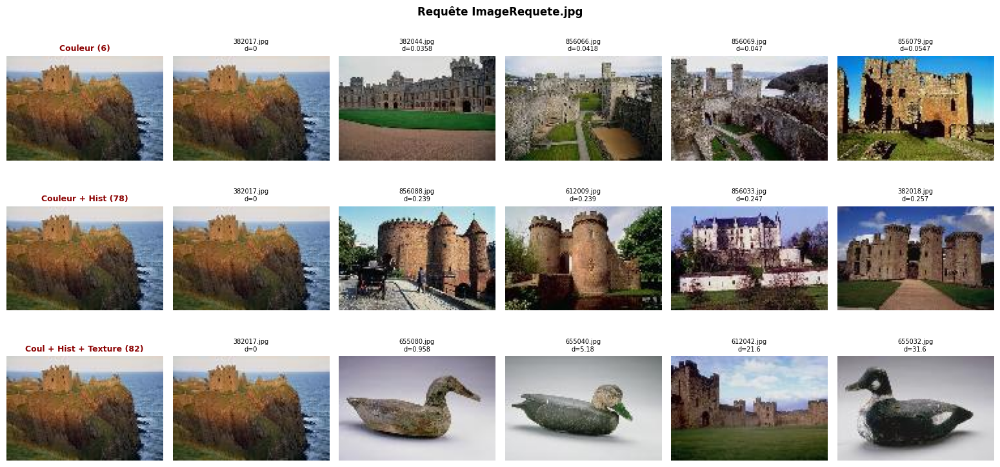

ImageRequete2.jpg — texture [contraste, corrélation, énergie, homogénéité] : [6.210016e+02 9.142000e-01 2.500000e-02 2.488000e-01]


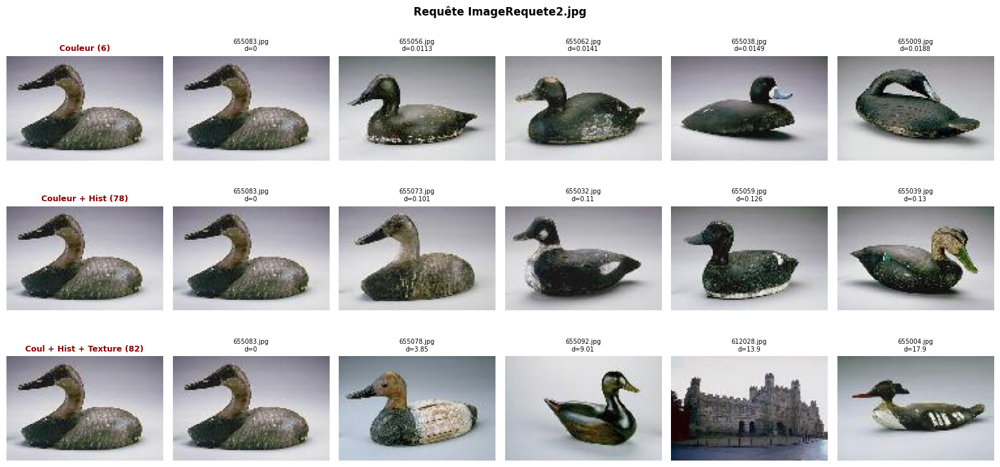

In [ ]:
#  3.5 Recherche par texture (GLCM)
def textureFeatures(img):
    """Contraste, corrélation, énergie, homogénéité de la GLCM (distance 1, moyenne sur 4 directions)."""
    gris = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    glcm = graycomatrix(gris, distances=[1], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                        levels=256, symmetric=True, normed=True)
    return np.array([graycoprops(glcm, p).mean() for p in ['contrast', 'correlation', 'energy', 'homogeneity']])

DESCRIPTEURS['texture'] = textureFeatures
DESCRIPTEURS_ACTIFS = ['couleur', 'histogramme', 'texture']
fsize = taille_vecteur()                                  # = 82
ind_coul_hist_tex, noms = CBIR_Indexation(fsize)

for nom_req, img_req in REQUETES.items():
    print(nom_req, '— texture [contraste, corrélation, énergie, homogénéité] :', np.round(textureFeatures(img_req), 4))
    RES[nom_req]['Coul + Hist + Texture (82)'] = CBIR_Recherche(img_req, ind_coul_hist_tex, noms)
    comparer(img_req, {k: RES[nom_req][k] for k in ['Couleur (6)', 'Couleur + Hist (78)', 'Coul + Hist + Texture (82)']}, nom_req)

### Interprétation — ajout de la texture GLCM (82 valeurs)

**Les résultats se dégradent nettement :**
- Pour la requête 1 (château), le système renvoie maintenant 3 leurres (`655080`, `655040`, `655032`) et un seul château (`612042`).
- Pour la requête 2 (leurre), un château (`612028`) apparaît en 4e position.

**Cause :** les 4 mesures GLCM n'ont pas du tout la même échelle.
- Le **contraste** vaut 390 pour la requête 1 et 621 pour la requête 2.
- La corrélation, l'énergie et l'homogénéité sont dans [0, 1], comme les moments de couleur et l'histogramme.

Dans la distance euclidienne, l'écart de contraste écrase tout le reste : la section 4.1 montre qu'il représente **100 %** de la distance totale. On voit d'ailleurs les distances passer de 0,2–0,3 à des valeurs de 1 à 30. La recherche revient donc à trier les images selon leur contraste, une seule valeur qui ne distingue pas un château d'un leurre (les deux ont des zones très contrastées).

**Confirmation chiffrée (4.6) :** la précision@5 tombe à 0,415, **exactement** le score de la GLCM seule. Les 78 valeurs de couleur n'ont plus aucun effet.

**Leçon :** concaténer des descripteurs hétérogènes sans normalisation n'est pas une fusion d'informations, c'est le descripteur de plus grande échelle qui décide.

**Remarque :** sur des images de 120×80 pixels, une GLCM à 256 niveaux de gris est très creuse. Quantifier en 16 ou 32 niveaux la rendrait plus stable.

<h2>3.6 Recherche par forme</h2>
La forme est un attribut fondamental pour décrire les objets dans une image. Elle permet de distinguer des objets même si leur couleur ou texture diffère. <br><br>
1. Créer un nouveau descripteur de forme en utlisant l'Histogramme des Orientations des Gradients (HOG). HOG capture la distribution des orientations locales des gradients sur toute l'image, ce qui permet de représenter à la fois les structures globales et les détails locaux de l'objet.<br>
Les étapes à suivre sont: <br>
   - Convertir l'image en niveaux de gris.<br>  
   - Découper l'image en blocs (par ex. 8×8 pixels). <br>
   - Calculer pour chaque bloc un histogramme des orientations (ex. 8  orientations).  <br>
   - Normaliser les blocs pour plus de robustesse.  <br>
   - Concaténer tous les histogrammes pour obtenir le vecteur final de caractéristiques.  <br>
<br>
2. Ajouter une fonction Python  « shapeFeaturesHOG » qui retourne le vecteur HOG à partir d'une image. <br>
<br>
3. Modifier la fonction  « getFeatures » pour concaténer le vecteur HOG avec les descripteurs existants de couleur, histogramme et texture<br>
<br>
4. Relancer l’indexation et la recherche CBIR avec ce nouveau vecteur complet.  
   Comparez les résultats avec et sans le descripteur HOG pour observer l’amélioration de la recherche basée sur la forme des objets, pour les deux imags requêtes.



Indexation ['couleur', 'histogramme', 'texture', 'forme'] : (270, 1650) en 13.6s


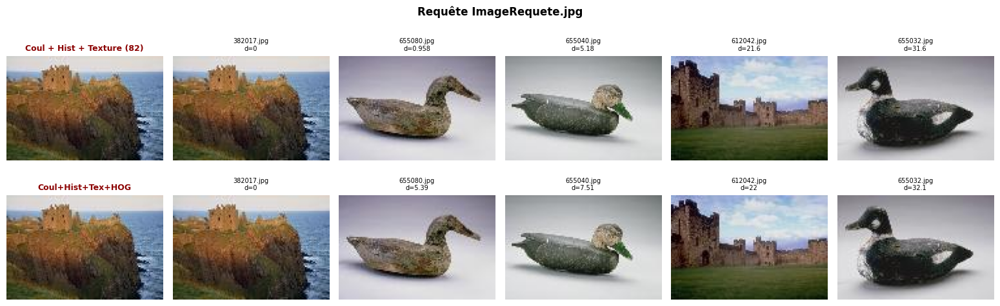

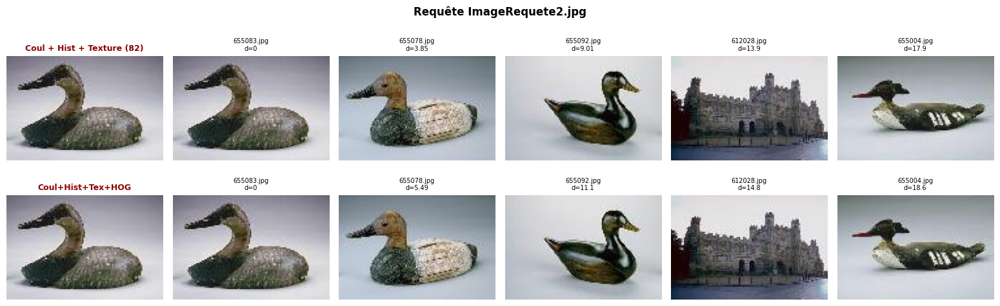

In [ ]:
#  3.6 Recherche par forme (HOG)
TAILLE_HOG = (128, 128)

def shapeFeaturesHOG(img):
    gris = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)                       # 1. niveaux de gris
    gris = cv2.resize(gris, TAILLE_HOG, interpolation=cv2.INTER_AREA)  # taille fixe -> vecteur de taille fixe
    return hog(gris,
               orientations=8,               # 3. histogramme de 8 orientations par cellule
               pixels_per_cell=(16, 16),     # 2. découpage en cellules
               cells_per_block=(2, 2),       # 4. normalisation par blocs de 2x2 cellules
               block_norm='L2-Hys',
               feature_vector=True)          # 5. concaténation -> 7*7*2*2*8 = 1568 valeurs

DESCRIPTEURS['forme'] = shapeFeaturesHOG
DESCRIPTEURS_ACTIFS = ['couleur', 'histogramme', 'texture', 'forme']
fsize = taille_vecteur()
ind_complet, noms = CBIR_Indexation(fsize)

for nom_req, img_req in REQUETES.items():
    RES[nom_req]['Coul+Hist+Tex+HOG'] = CBIR_Recherche(img_req, ind_complet, noms)
    comparer(img_req, {k: RES[nom_req][k] for k in ['Coul + Hist + Texture (82)', 'Coul+Hist+Tex+HOG']}, nom_req)

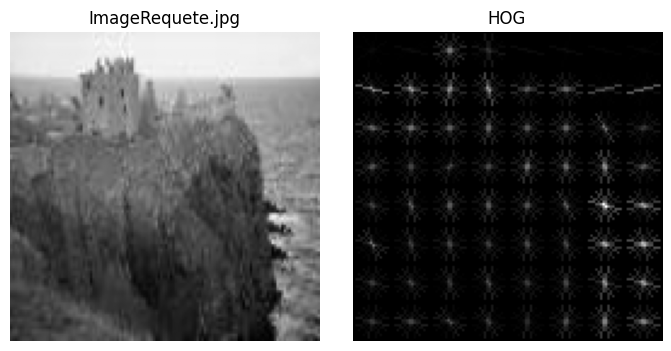

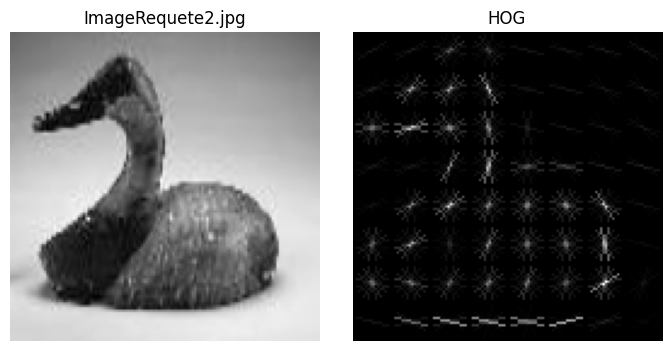

In [11]:
# Visualisation du HOG des images requête (aide à l'interprétation)
for nom_req, img_req in REQUETES.items():
    gris = cv2.resize(cv2.cvtColor(img_req, cv2.COLOR_RGB2GRAY), TAILLE_HOG)
    _, vis = hog(gris, orientations=8, pixels_per_cell=(16, 16), cells_per_block=(2, 2), visualize=True)
    fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
    ax[0].imshow(gris, cmap='gray'); ax[0].set_title(nom_req); ax[1].imshow(vis, cmap='gray'); ax[1].set_title('HOG')
    for a in ax: a.axis('off')
    plt.tight_layout(); plt.show()

### Interprétation — ajout de la forme HOG (1 650 valeurs au total)

- **Aucun changement :** le classement est **identique** à celui de 3.5 pour les deux requêtes (mêmes images, dans le même ordre). Seules les distances augmentent légèrement.
- **Sur toute la base :** P@5 = 0,416 contre 0,415, donc aucun gain.
- **Cause :** la même qu'en 3.5. Même avec 1 568 valeurs, le bloc HOG ne pèse qu'environ 22 dans la distance², contre environ 507 850 pour la texture (tableau 4.1). Le contraste GLCM continue de tout décider.
- **HOG est pourtant un bon descripteur :** utilisé seul (section 4.5), il retrouve pour le leurre des images **de même silhouette et de même orientation** (`655075`, `655073`, `655058`, `655045`, tous tête à gauche), et pour le château uniquement des châteaux. Sa précision@5 seul vaut 0,549.
- **Ce que montre la visualisation HOG :**
  - Sur le leurre, les gradients dessinent nettement le contour de la tête, du cou et du dos sur le fond uniforme : c'est une vraie information de forme.
  - Sur le château, les gradients sont nombreux et dispersés (pierres, falaise, vagues), donc plus proches d'une texture que d'une forme.
- **Conclusion :** l'amélioration attendue avec HOG n'apparaît qu'une fois les descripteurs normalisés et pondérés. On le voit en 4.1 : avec la recherche pondérée, la requête 1 renvoie 4 châteaux et la requête 2 renvoie 5 leurres.

<h2>3.7	Robustesse vis-à-vis des transformations géométriques</h2>
La robustesse des systèmes CBIR est testée en présence des transformations géométriques ; à savoir la translation, la rotation et le changement d’échelle.
 Appliquer quelques transformations géométriques aux images requêtes et relancer la recherche. Interpréter les résultat de recherche.

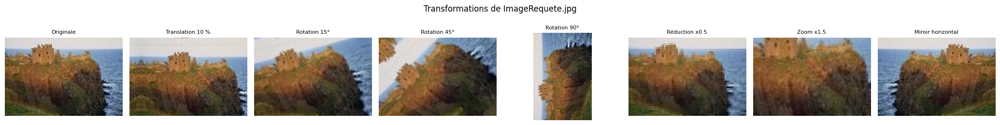

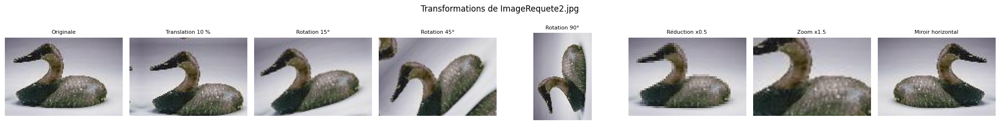

In [ ]:
#  3.7 Robustesse vis-à-vis des transformations géométriques 
# Les bords sont complétés en miroir (BORDER_REFLECT) pour ne pas introduire de zones noires qui fausseraient les descripteurs de couleur et de texture.
def translation(img, fx=0.1, fy=0.1):
    """Décalage de 10 % de la largeur et de la hauteur."""
    h, w = img.shape[:2]
    M = np.float32([[1, 0, fx * w], [0, 1, fy * h]])
    return cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)

def rotation(img, angle):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    return cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)

def reduction(img, f=0.5):
    return cv2.resize(img, None, fx=f, fy=f, interpolation=cv2.INTER_AREA)  # même contenu, image plus petite

def zoom(img, f=1.5):
    """Agrandissement : on garde le centre (1/f de l'image) puis on remet à la taille d'origine."""
    h, w = img.shape[:2]; ch, cw = int(h / f), int(w / f)
    y0, x0 = (h - ch) // 2, (w - cw) // 2
    return cv2.resize(img[y0:y0+ch, x0:x0+cw], (w, h), interpolation=cv2.INTER_LINEAR)

TRANSFORMATIONS = {
    'Originale':          lambda im: im,
    'Translation 10 %':   translation,
    'Rotation 15 deg':       lambda im: rotation(im, 15),
    'Rotation 45 deg':       lambda im: rotation(im, 45),
    'Rotation 90 deg':       lambda im: np.ascontiguousarray(np.rot90(im)),
    'Réduction x0.5':     reduction,
    'Zoom x1.5':          zoom,
    'Miroir horizontal':  lambda im: np.ascontiguousarray(im[:, ::-1]),
}

for nom_req, img_req in REQUETES.items():
    fig, axes = plt.subplots(1, len(TRANSFORMATIONS), figsize=(2.6 * len(TRANSFORMATIONS), 2.6))
    for ax, (t, f) in zip(axes, TRANSFORMATIONS.items()):
        ax.imshow(f(img_req)); ax.set_title(t, fontsize=8); ax.axis('off')
    plt.suptitle(f'Transformations de {nom_req}'); plt.tight_layout(); plt.show()

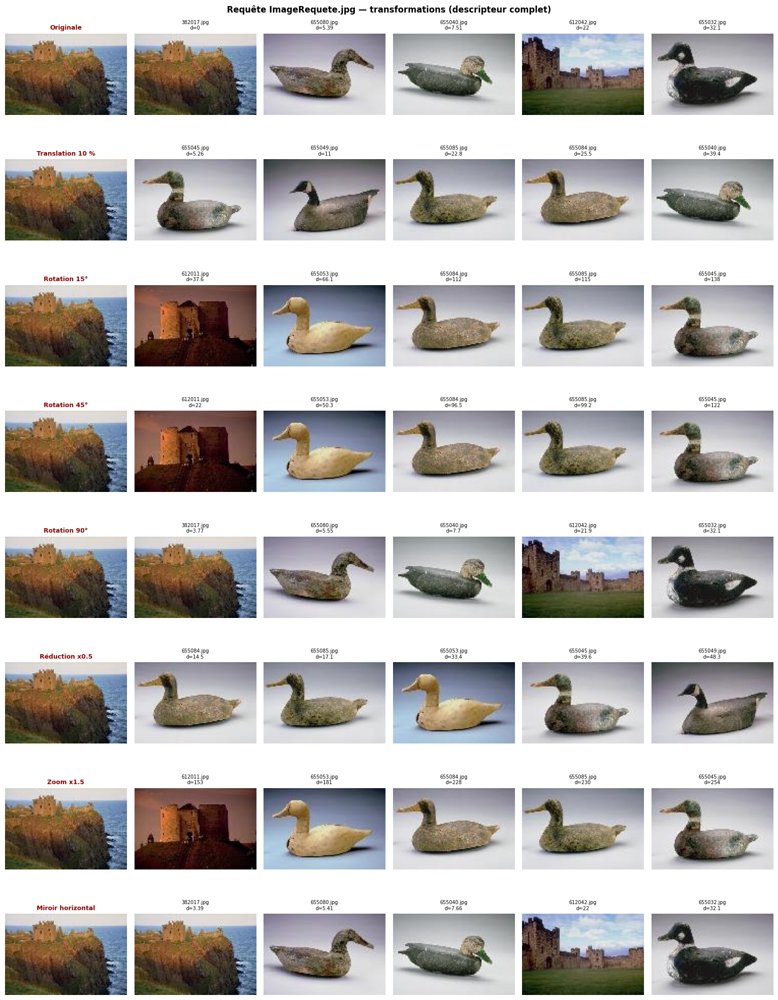

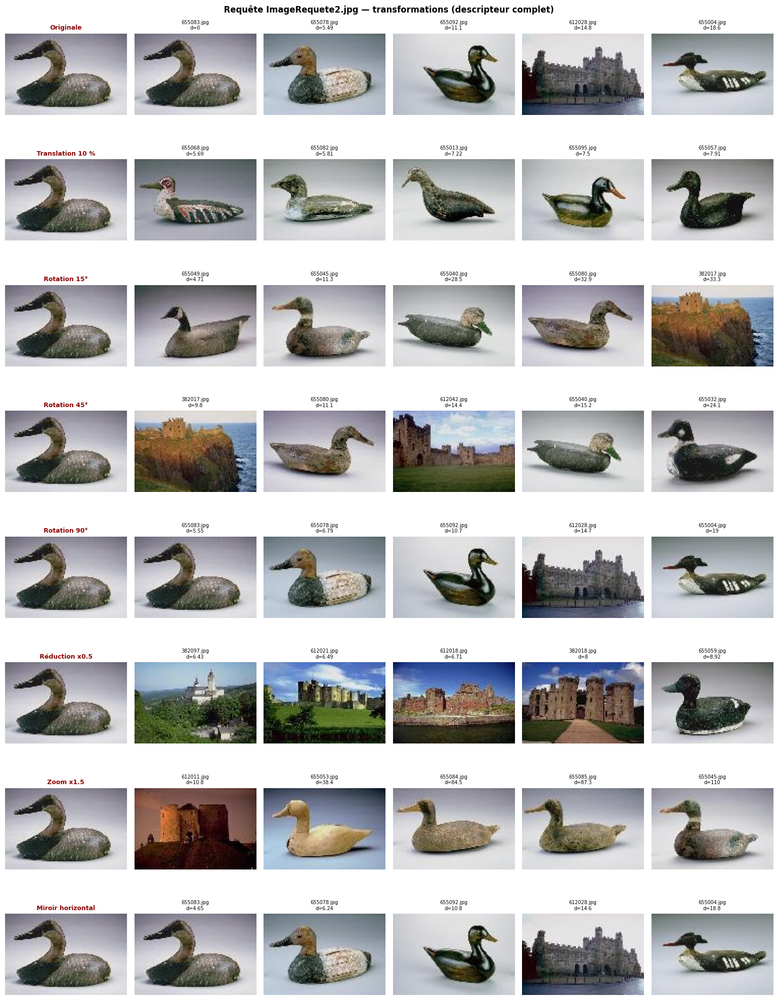

In [30]:
# Recherche avec le descripteur complet (couleur + histogramme + texture + HOG) sur les requêtes transformées
DESCRIPTEURS_ACTIFS = ['couleur', 'histogramme', 'texture', 'forme']
RES_TRANSFO = {}
for nom_req, img_req in REQUETES.items():
    RES_TRANSFO[nom_req] = {t: CBIR_Recherche(f(img_req), ind_complet, noms) for t, f in TRANSFORMATIONS.items()}
    comparer(img_req, RES_TRANSFO[nom_req], nom_req + ' — transformations (descripteur complet)')

In [31]:
# Mesure quantitative : parmi les 10 premiers résultats obtenus avec la requête originale,
# combien sont retrouvés avec la requête transformée ? (1.0 = parfaitement robuste)
def recherche_simple(img, descripteurs):
    """Recherche euclidienne sur un sous-ensemble de descripteurs (index pré-calculé une seule fois)."""
    q = np.concatenate([DESCRIPTEURS[d](img) for d in descripteurs])
    M = np.hstack([BLOCS[d] for d in descripteurs])
    dist = np.linalg.norm(M - q, axis=1)
    o = np.argsort(dist)
    return [(NOMS[i], float(dist[i])) for i in o]

# Index par descripteur (calculé une fois, réutilisé dans toute la suite)
BLOCS = {d: np.array([f(IMAGES[n]) for n in NOMS]) for d, f in DESCRIPTEURS.items()}

def recouvrement(res_a, res_b, k=10):
    return len({n for n, _ in res_a[:k]} & {n for n, _ in res_b[:k]}) / k

CONFIGS_ROB = {'Couleur': ['couleur'], 'Histogramme': ['histogramme'], 'Texture': ['texture'],
               'HOG': ['forme'], 'Complet': ['couleur', 'histogramme', 'texture', 'forme']}
for nom_req, img_req in REQUETES.items():
    ref = {c: recherche_simple(img_req, ds) for c, ds in CONFIGS_ROB.items()}
    tab = pd.DataFrame({c: {t: recouvrement(ref[c], recherche_simple(f(img_req), ds))
                            for t, f in TRANSFORMATIONS.items()} for c, ds in CONFIGS_ROB.items()})
    print(f'\nRequête {nom_req} — recouvrement du top 10 avec la requête originale')
    display(tab.style.background_gradient(cmap='RdYlGn', vmin=0, vmax=1).format('{:.1f}'))


Requête ImageRequete.jpg — recouvrement du top 10 avec la requête originale


,Couleur,Histogramme,Texture,HOG,Complet
Originale,1.0,1.0,1.0,1.0,1.0
Translation 10 %,0.2,0.9,0.7,0.7,0.7
Rotation 15°,0.8,1.0,0.6,0.5,0.6
Rotation 45°,0.7,1.0,0.6,0.3,0.6
Rotation 90°,1.0,1.0,1.0,0.2,1.0
Réduction x0.5,1.0,1.0,0.6,0.9,0.6
Zoom x1.5,0.0,0.9,0.6,0.3,0.6
Miroir horizontal,1.0,1.0,1.0,0.3,1.0



Requête ImageRequete2.jpg — recouvrement du top 10 avec la requête originale


,Couleur,Histogramme,Texture,HOG,Complet
Originale,1.0,1.0,1.0,1.0,1.0
Translation 10 %,0.0,0.4,0.0,0.0,0.0
Rotation 15°,1.0,0.7,0.0,0.5,0.0
Rotation 45°,0.2,0.6,0.0,0.0,0.0
Rotation 90°,1.0,1.0,1.0,0.0,0.9
Réduction x0.5,0.9,1.0,0.0,1.0,0.0
Zoom x1.5,0.0,0.3,0.0,0.2,0.0
Miroir horizontal,1.0,1.0,1.0,0.0,0.9


### Interprétation — robustesse aux transformations géométriques

Le tableau mesure la proportion des 10 premiers résultats qui restent identiques entre la requête originale et la requête transformée. Les bords créés par la translation et les rotations sont complétés **en miroir** (`BORDER_REFLECT`). Avec des bords noirs, on ajoutait des pixels artificiels qui faussaient la couleur et le contraste. Par exemple, pour la requête 1, l'histogramme passait de 0,4 avec bords noirs à 0,9 avec bords en miroir pour la translation, et les moments de couleur de 0,0 à 0,8 pour la rotation de 15°.

**Rotation de 90° et miroir horizontal**
- La couleur, l'histogramme et la texture restent à **1,0** pour les deux requêtes. Ce sont des statistiques globales qui ne dépendent pas de la position des pixels, et ces transformations ne font que les permuter. La GLCM, moyennée sur 4 directions (0°, 45°, 90°, 135°), est elle aussi insensible à une rotation de 90° ou à un miroir.
- **HOG n'est pas invariant** (0,2 et 0,0 pour la rotation de 90° ; 0,3 et 0,0 pour le miroir). Les orientations des gradients tournent avec l'image, et chaque cellule décrit une position fixe.

**Translation de 10 % et petites rotations**
- **Requête 1 :** l'histogramme HSV est le plus robuste (0,9 à 1,0), car le miroir ne fait que redistribuer des couleurs déjà présentes. Les moments de couleur restent stables pour les rotations (0,8 et 0,7), mais pas pour la translation (0,2). HOG se dégrade avec l'angle (0,7, puis 0,5, puis 0,3), puisque les contours changent de cellule et d'orientation.
- **Requête 2 :** les recouvrements sont beaucoup plus faibles, par exemple 0,0 pour la couleur après translation. Pourtant, la figure montre que les 5 résultats après translation sont **toujours des leurres**. Les leurres sont tous très proches entre eux : les distances de couleur des premiers résultats vont de 0,011 à 0,019. La moindre perturbation réordonne donc complètement le top 10, sans pour autant faire sortir de la bonne catégorie. Le recouvrement est une mesure stricte : il dit si le classement est **identique**, pas s'il reste **pertinent**.

**Réduction ×0,5**
- La couleur et l'histogramme ne changent pas (0,9 à 1,0), car les proportions de couleurs sont conservées.
- HOG reste stable (0,9 et 1,0) parce que l'image est de toute façon redimensionnée en 128×128 avant le calcul.
- La texture chute (0,6 et 0,0) : la GLCM compare des pixels voisins à une distance d'un pixel, et réduire l'image change les motifs observés à cette distance. Pour la requête 2, le descripteur complet renvoie alors 4 châteaux.

**Zoom ×1,5 :** tous les descripteurs changent, ce qui est normal puisque le recadrage supprime une partie du contenu (le fond gris, le ciel, la mer).

**Descripteur complet :** il se comporte exactement comme la colonne « Texture », car le contraste GLCM domine toujours la distance (voir 3.5 et 4.1). Sa robustesse est donc celle de la GLCM, et non celle du meilleur descripteur. Pour la requête 1, il renvoie déjà des leurres sans aucune transformation.

<h2>4 Améliorations</h2>

Pistes proposées dans le sujet, implémentées ci-dessous :

1. **Normalisation et pondération des descripteurs** : dans la concaténation brute, les blocs n'ont ni la même taille ni la même échelle.
2. **Autres espaces de couleur** : RGB, HSV, Lab.
3. **Distances adaptées aux histogrammes** : χ², intersection, Bhattacharyya.
4. **Autres descripteurs de texture** : filtres de Gabor, LBP.
5. **Autre descripteur de forme** : moments de Hu.
6. **Évaluation quantitative** : précision@k et mAP sur toute la base.
7. **Interface graphique** : soumission d'une image requête et affichage des résultats.

<h3>4.1 Poids réel de chaque descripteur dans la concaténation brute</h3>

In [15]:
# Contribution moyenne de chaque bloc à la distance euclidienne² dans le vecteur concaténé brut
contrib = {}
for d in ['couleur', 'histogramme', 'texture', 'forme']:
    M = BLOCS[d]
    diff2 = ((M[:, None, :] - M[None, :, :]) ** 2).sum(-1) if M.shape[1] < 200 else \
            np.array([((M - M[i]) ** 2).sum(1) for i in range(len(M))])
    contrib[d] = diff2.mean()
s = pd.Series(contrib); pct = 100 * s / s.sum()
display(pd.DataFrame({'dimension': {d: BLOCS[d].shape[1] for d in s.index},
                      'distance² moyenne': s.round(4), '% de la distance totale': pct.round(1)}))

,dimension,distance² moyenne,% de la distance totale
couleur,6,0.0735,0.0
histogramme,72,0.1880,0.0
texture,4,507849.6427,100.0
forme,1568,22.2065,0.0


**Solution** : calculer une distance par descripteur, la diviser par sa médiane sur la base (pour la requête courante), puis faire une somme pondérée. Chaque descripteur pèse alors le même poids (ou le poids qu'on choisit), quelles que soient sa taille et son échelle, et on peut utiliser la distance la plus adaptée à chaque bloc.

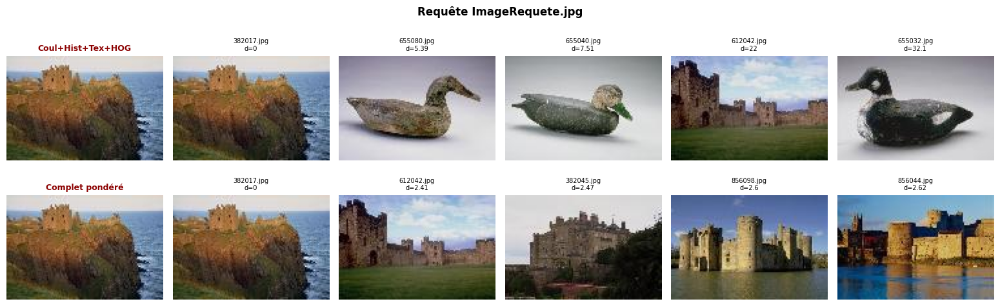

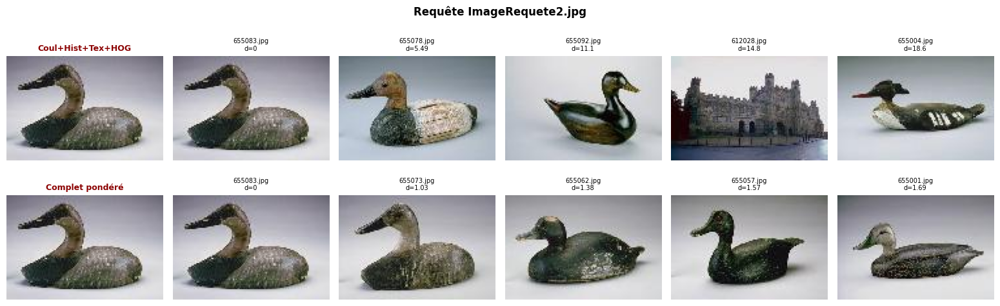

In [16]:
def distance(q, M, metrique='euclidienne'):
    """Distance entre un vecteur q et chaque ligne de M."""
    eps = 1e-10
    if metrique == 'euclidienne':  return np.linalg.norm(M - q, axis=1)
    if metrique == 'manhattan':    return np.abs(M - q).sum(1)
    if metrique == 'cosinus':      return 1 - (M @ q) / (np.linalg.norm(M, axis=1) * np.linalg.norm(q) + eps)
    if metrique == 'chi2':         return 0.5 * ((M - q) ** 2 / (M + q + eps)).sum(1)
    if metrique == 'intersection': return 1 - np.minimum(M, q).sum(1) / (q.sum() + eps)
    if metrique == 'bhattacharyya':
        bc = np.sqrt(M * q).sum(1) / np.sqrt(M.sum(1) * q.sum() + eps)
        return np.sqrt(np.clip(1 - bc, 0, None))
    raise ValueError(metrique)

def recherche_ponderee(img, config, exclure=None, q_blocs=None):
    """config = {descripteur: (metrique, poids)}. Chaque distance est divisée par sa médiane."""
    total = np.zeros(len(NOMS))
    for d, (metrique, poids) in config.items():
        q = q_blocs[d] if q_blocs is not None else DESCRIPTEURS[d](img)
        dist = distance(q, BLOCS[d], metrique)
        total += poids * dist / (np.median(dist) + 1e-10)
    if exclure is not None: total[exclure] = np.inf
    o = np.argsort(total)
    return [(NOMS[i], float(total[i])) for i in o]

CONF_BRUTE    = None  # la concaténation brute de l'énoncé (CBIR_Recherche)
CONF_EQUILIBRE = {'couleur': ('euclidienne', 1), 'histogramme': ('euclidienne', 1),
                  'texture': ('euclidienne', 1), 'forme': ('euclidienne', 1)}
for nom_req, img_req in REQUETES.items():
    RES[nom_req]['Complet pondéré'] = recherche_ponderee(img_req, CONF_EQUILIBRE)
    comparer(img_req, {k: RES[nom_req][k] for k in ['Coul+Hist+Tex+HOG', 'Complet pondéré']}, nom_req)

### Interprétation — normalisation et pondération

- **Mesure du déséquilibre :** le tableau quantifie ce qu'on avait supposé en 3.5 et 3.6. La distance² moyenne vaut environ **507 850** pour la texture, contre 22 pour HOG, 0,19 pour l'histogramme et 0,07 pour la couleur. La texture représente donc 100 % de la distance totale. La **dimension** d'un bloc ne dit rien de son poids réel, c'est son **échelle** qui compte : HOG, avec 1 568 valeurs, pèse 20 000 fois moins que les 4 valeurs GLCM.
- **Correction appliquée :**
  1. On calcule une distance séparée pour chaque descripteur.
  2. On la divise par sa médiane sur la base, ce qui donne une valeur sans unité, autour de 1.
  3. On additionne les distances ainsi normalisées.
- **Effet visuel :**
  - Requête 1 : on obtient **4 châteaux** (`612042`, `382045`, `856098`, `856044`) au lieu de 3 leurres.
  - Requête 2 : on obtient **5 leurres** d'apparence très proche, au lieu de 4 leurres et un château.
- **Effet chiffré (4.6) :** la mAP passe de **0,403** (concaténation brute) à **0,509** avec exactement les mêmes 4 descripteurs. On obtient une amélioration de 26 % sans ajouter aucune information, simplement en combinant correctement.

Une alternative classique serait de standardiser chaque dimension (z-score). La normalisation par bloc a l'avantage de donner le même poids à chaque **descripteur**, indépendamment de sa dimension.

<h3>4.2 Autres espaces de couleur</h3>

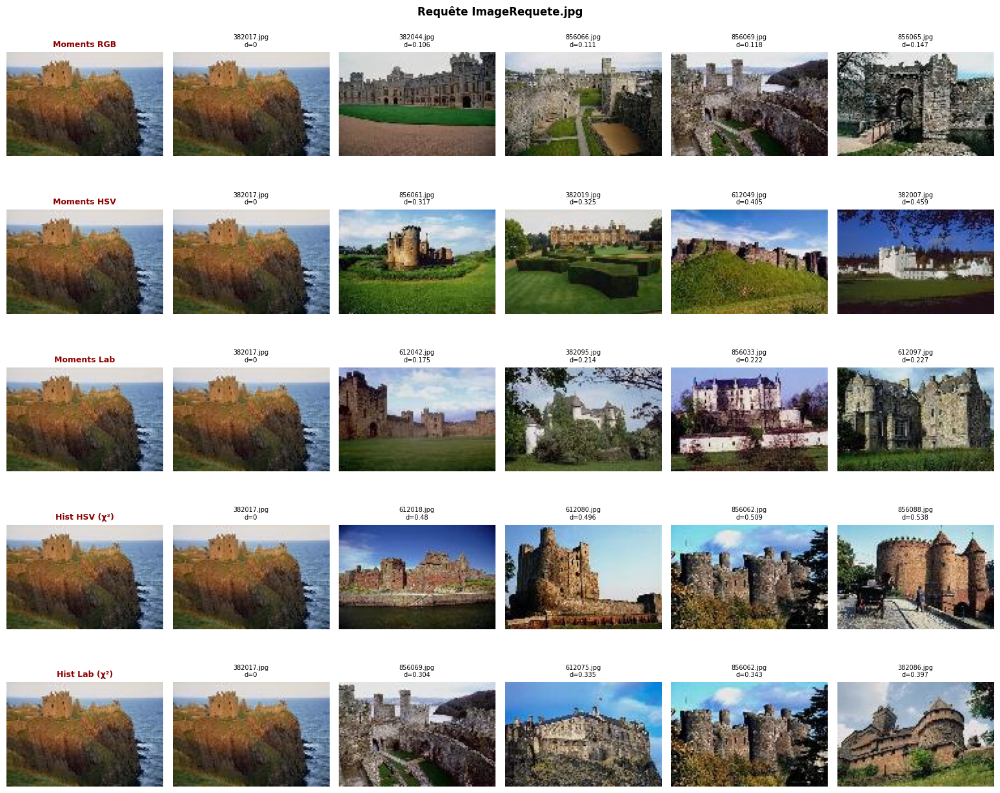

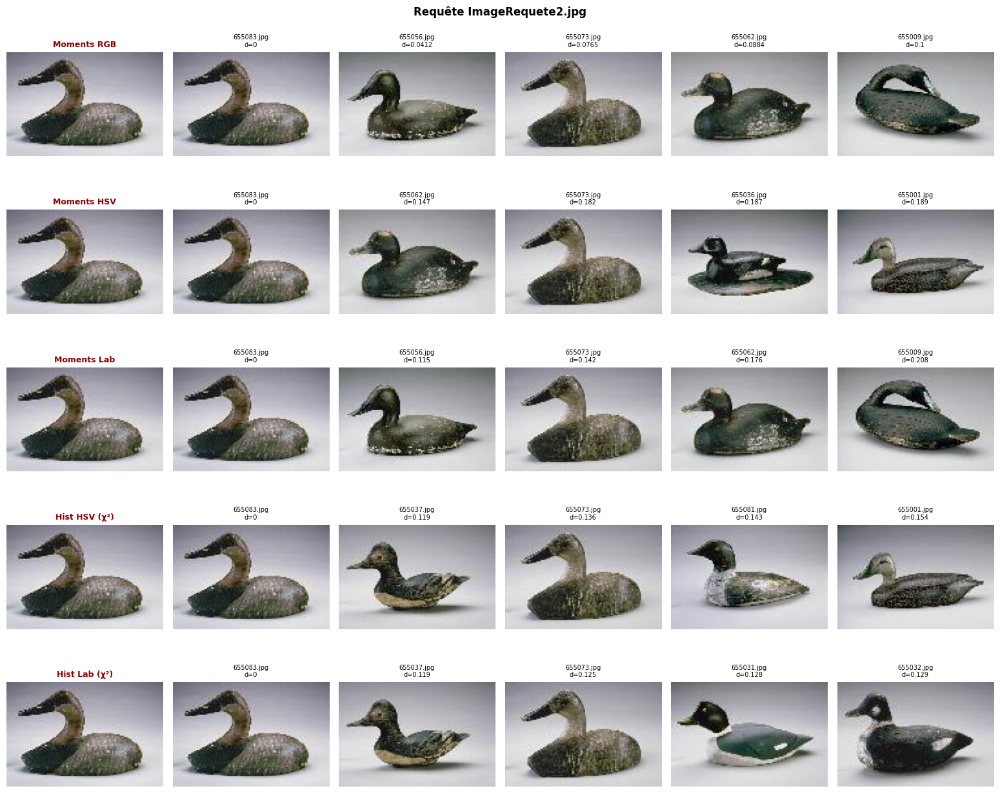

In [17]:
def moments_espace(espace):
    conv = {'RGB': None, 'HSV': cv2.COLOR_RGB2HSV, 'Lab': cv2.COLOR_RGB2LAB}[espace]
    def f(img):
        x = (img if conv is None else cv2.cvtColor(img, conv)).reshape(-1, 3).astype(np.float64) / 255.0
        # moyenne, écart-type et asymétrie (3e moment) par canal : 9 valeurs
        mu, sd = x.mean(0), x.std(0)
        skew = np.cbrt(((x - mu) ** 3).mean(0))
        return np.concatenate([mu, sd, skew])
    return f

def labHistogram(img, bins=(4, 6, 6)):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    h = cv2.calcHist([lab], [0, 1, 2], None, list(bins), [0, 256, 0, 256, 0, 256]).ravel()
    return h / h.sum()

for e in ['RGB', 'HSV', 'Lab']:
    DESCRIPTEURS[f'moments_{e}'] = moments_espace(e)
DESCRIPTEURS['hist_Lab'] = labHistogram
for d in ['moments_RGB', 'moments_HSV', 'moments_Lab', 'hist_Lab']:
    BLOCS[d] = np.array([DESCRIPTEURS[d](IMAGES[n]) for n in NOMS])

for nom_req, img_req in REQUETES.items():
    comparer(img_req, {
        'Moments RGB':   recherche_ponderee(img_req, {'moments_RGB': ('euclidienne', 1)}),
        'Moments HSV':   recherche_ponderee(img_req, {'moments_HSV': ('euclidienne', 1)}),
        'Moments Lab':   recherche_ponderee(img_req, {'moments_Lab': ('euclidienne', 1)}),
        'Hist HSV (χ²)': recherche_ponderee(img_req, {'histogramme': ('chi2', 1)}),
        'Hist Lab (χ²)': recherche_ponderee(img_req, {'hist_Lab': ('chi2', 1)}),
    }, nom_req)

<h3>4.3 Distances adaptées aux histogrammes</h3>

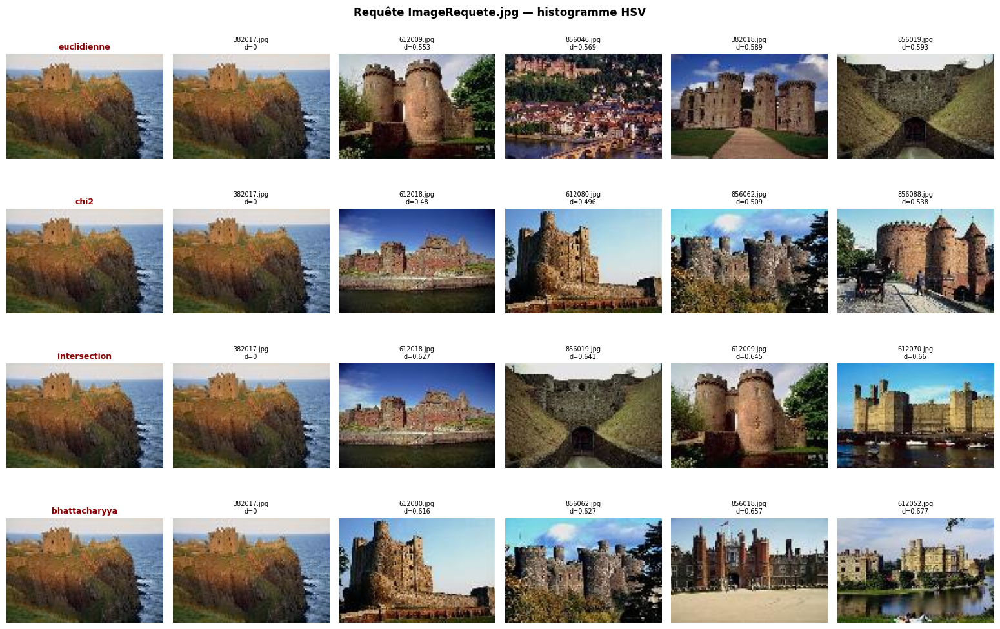

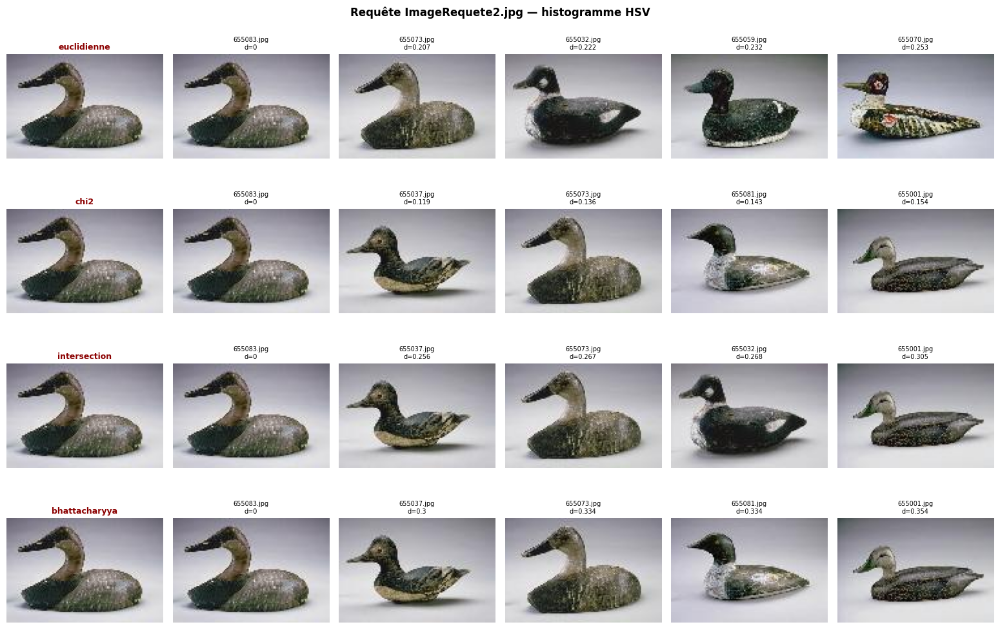

In [18]:
for nom_req, img_req in REQUETES.items():
    comparer(img_req, {m: recherche_ponderee(img_req, {'histogramme': (m, 1)})
                       for m in ['euclidienne', 'chi2', 'intersection', 'bhattacharyya']}, nom_req + ' — histogramme HSV')

<h3>4.4 Autres descripteurs de texture : Gabor et LBP</h3>

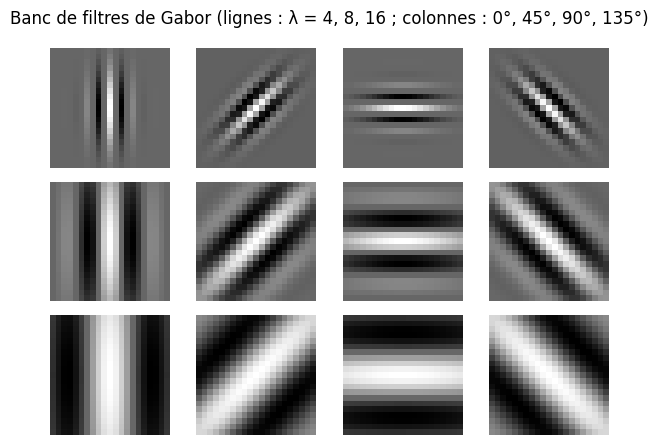

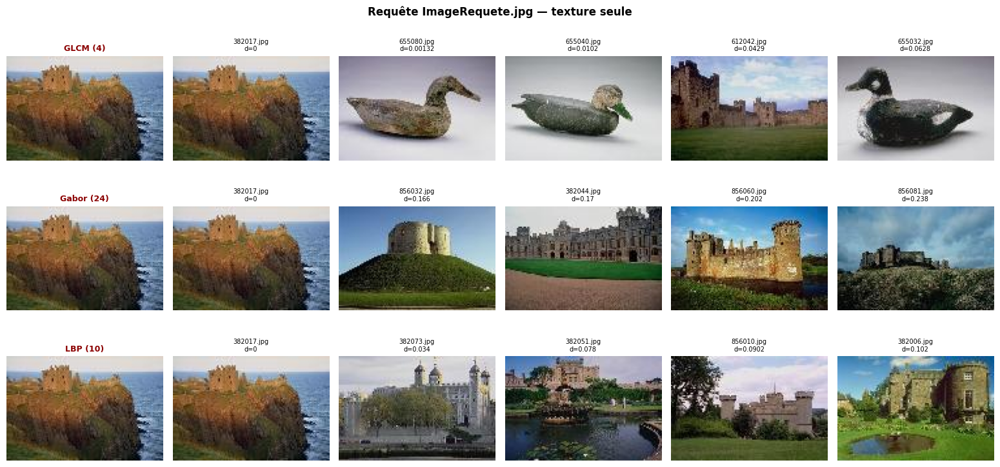

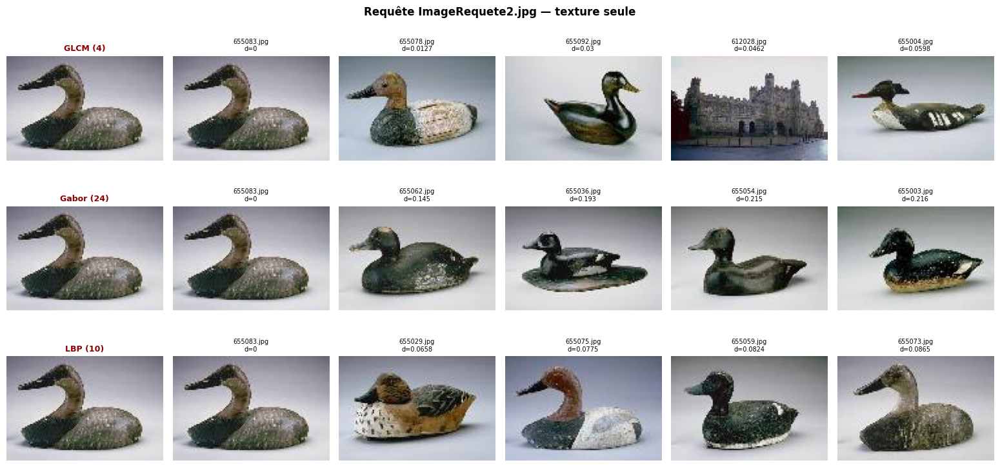

In [19]:
# Banc de filtres de Gabor : 4 orientations x 3 longueurs d'onde -> moyenne et écart-type de la réponse = 24 valeurs
NOYAUX_GABOR = [cv2.getGaborKernel((21, 21), sigma=0.56 * lam, theta=th, lambd=lam, gamma=0.5, psi=0)
                for lam in (4, 8, 16) for th in np.arange(0, np.pi, np.pi / 4)]

def gaborFeatures(img):
    g = cv2.resize(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), (128, 128)).astype(np.float32) / 255.0
    f = []
    for k in NOYAUX_GABOR:
        r = np.abs(cv2.filter2D(g, cv2.CV_32F, k))
        f += [r.mean(), r.std()]
    return np.array(f)

def lbpFeatures(img, P=8, R=1):
    """Histogramme des motifs binaires locaux uniformes, invariants en rotation (P+2 = 10 cases)."""
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    lbp = local_binary_pattern(g, P, R, method='uniform')
    h, _ = np.histogram(lbp, bins=np.arange(P + 3), density=True)
    return h

# Fenêtre de Gabor : visualisation du banc de filtres
fig, axes = plt.subplots(3, 4, figsize=(6, 4.5))
for ax, k in zip(axes.ravel(), NOYAUX_GABOR): ax.imshow(k, cmap='gray'); ax.axis('off')
plt.suptitle('Banc de filtres de Gabor (lignes : λ = 4, 8, 16 ; colonnes : 0°, 45°, 90°, 135°)'); plt.tight_layout(); plt.show()

DESCRIPTEURS['gabor'] = gaborFeatures; DESCRIPTEURS['lbp'] = lbpFeatures
for d in ['gabor', 'lbp']:
    BLOCS[d] = np.array([DESCRIPTEURS[d](IMAGES[n]) for n in NOMS])

for nom_req, img_req in REQUETES.items():
    comparer(img_req, {
        'GLCM (4)':  recherche_ponderee(img_req, {'texture': ('euclidienne', 1)}),
        'Gabor (24)': recherche_ponderee(img_req, {'gabor': ('euclidienne', 1)}),
        'LBP (10)':   recherche_ponderee(img_req, {'lbp': ('chi2', 1)}),
    }, nom_req + ' — texture seule')

<h3>4.5 Autre descripteur de forme : moments de Hu</h3>

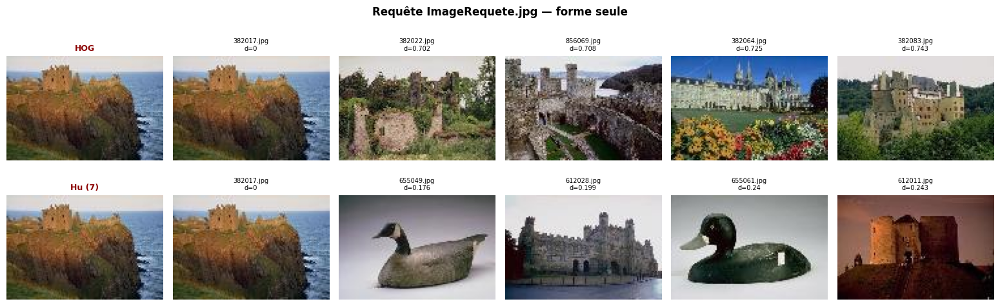

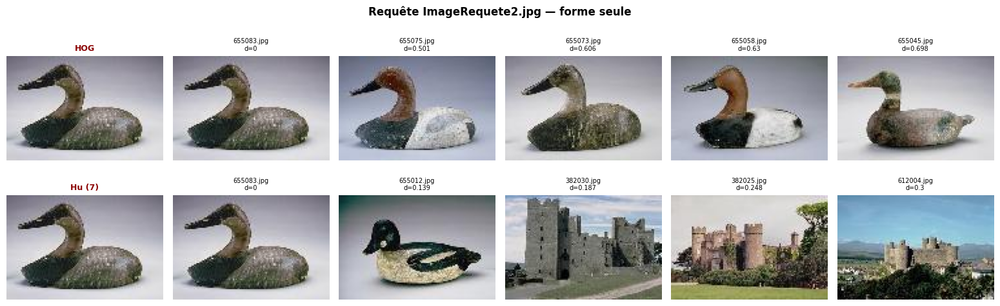


Requête ImageRequete.jpg — recouvrement du top 10


,HOG,Hu,Gabor,LBP,Hist HSV χ²
Originale,1.0,1.0,1.0,1.0,1.0
Translation 10 %,0.7,1.0,0.2,0.2,0.7
Rotation 15°,0.5,0.9,0.9,0.0,0.9
Rotation 45°,0.3,0.1,0.8,0.0,0.8
Rotation 90°,0.2,1.0,1.0,1.0,1.0
Réduction x0.5,0.9,0.8,0.9,0.2,0.9
Zoom x1.5,0.3,0.7,0.0,0.0,0.7
Miroir horizontal,0.3,0.6,1.0,1.0,1.0



Requête ImageRequete2.jpg — recouvrement du top 10


,HOG,Hu,Gabor,LBP,Hist HSV χ²
Originale,1.0,1.0,1.0,1.0,1.0
Translation 10 %,0.0,0.0,0.0,0.6,0.7
Rotation 15°,0.5,0.0,0.8,0.5,1.0
Rotation 45°,0.0,0.0,0.3,0.1,0.9
Rotation 90°,0.0,0.9,0.3,1.0,1.0
Réduction x0.5,1.0,0.0,1.0,0.2,1.0
Zoom x1.5,0.2,0.0,0.0,0.2,0.4
Miroir horizontal,0.0,0.0,0.6,1.0,1.0


In [32]:
def huMoments(img):
    """7 moments de Hu (invariants en translation, rotation, échelle) calculés sur la carte des contours."""
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    contours = cv2.Canny(cv2.GaussianBlur(g, (5, 5), 0), 50, 150)
    hu = cv2.HuMoments(cv2.moments(contours, binaryImage=True)).ravel()
    return -np.sign(hu) * np.log10(np.abs(hu) + 1e-30)     # échelle log : sinon les valeurs vont de 1e-1 à 1e-20

DESCRIPTEURS['hu'] = huMoments
BLOCS['hu'] = np.array([huMoments(IMAGES[n]) for n in NOMS])

for nom_req, img_req in REQUETES.items():
    comparer(img_req, {
        'HOG':      recherche_ponderee(img_req, {'forme': ('euclidienne', 1)}),
        'Hu (7)':   recherche_ponderee(img_req, {'hu': ('euclidienne', 1)}),
    }, nom_req + ' — forme seule')

# Robustesse comparée HOG / Hu / LBP / Gabor (même mesure qu'en 3.7)
for nom_req, img_req in REQUETES.items():
    tab = {}
    for c, conf in {'HOG': {'forme': ('euclidienne', 1)}, 'Hu': {'hu': ('euclidienne', 1)},
                    'Gabor': {'gabor': ('euclidienne', 1)}, 'LBP': {'lbp': ('chi2', 1)},
                    'Hist HSV χ²': {'histogramme': ('chi2', 1)}}.items():
        ref = recherche_ponderee(img_req, conf)
        tab[c] = {t: recouvrement(ref, recherche_ponderee(f(img_req), conf)) for t, f in TRANSFORMATIONS.items()}
    print(f'\nRequête {nom_req} — recouvrement du top 10')
    display(pd.DataFrame(tab).style.background_gradient(cmap='RdYlGn', vmin=0, vmax=1).format('{:.1f}'))

### Interprétation — améliorations des descripteurs (4.2 à 4.5)

**Espaces de couleur (4.2)**
- RGB, HSV et Lab retrouvent tous des châteaux pour la requête 1 et des leurres pour la requête 2, mais chacun avec des images différentes.
- Sur la base complète, les moments Lab (mAP 0,498) sont équivalents aux moments RGB de l'énoncé (0,504). Lab est conçu pour que les distances correspondent aux écarts de couleur perçus, ce qui est utile mais ne change pas la nature du descripteur. Les moments HSV posent un problème théorique : la teinte est circulaire (0 et 180 sont le même rouge), donc sa moyenne n'a pas de sens pour les teintes rouges.
- Les histogrammes HSV et Lab donnent la même précision@5 (0,584 et 0,585). HSV a une meilleure mAP (0,473 contre 0,447).

**Distances pour histogrammes (4.3)**
- Avec la distance euclidienne, la requête 1 fait remonter en 2e position une vue de ville aux toits rouges (`856046`). Les distances χ², intersection et Bhattacharyya ne renvoient que des châteaux.
- La distance euclidienne traite toutes les cases de l'histogramme de la même façon, alors que les autres sont conçues pour comparer des distributions. Le χ², par exemple, mesure les écarts **relativement** à la taille de la case, si bien que les teintes peu présentes comptent aussi.
- Sur la requête 2, les quatre distances donnent des résultats proches : elles retrouvent toutes les mêmes leurres (`655037`, `655073`, `655001`…).

**Texture : Gabor et LBP (4.4)**
- Ces deux descripteurs sont bien meilleurs que la GLCM. Pour la requête 1, ils renvoient 5 châteaux au lieu de 3 leurres ; pour la requête 2, uniquement des leurres.
- mAP : GLCM 0,403, Gabor 0,491, **LBP 0,536**. LBP est le meilleur descripteur pris isolément, si on met à part l'image entière.
- Les deux sont normalisés par construction (histogramme de motifs pour LBP, réponses de filtres dans [0, 1] pour Gabor) et décrivent la texture à plusieurs orientations (et plusieurs échelles pour Gabor), alors que la GLCM se résume ici à 4 nombres très corrélés.
- Robustesse : LBP « uniforme » est invariant à la rotation de 90° et au miroir (1,0 pour les deux requêtes), mais sensible au changement d'échelle (0,2 pour les deux requêtes). Les motifs sont calculés sur un voisinage d'un pixel, qui ne recouvre plus les mêmes structures quand on réduit l'image.

**Forme : moments de Hu (4.5)**
- C'est le moins bon descripteur (mAP **0,296**, à peine au-dessus du hasard, ≈ 0,26). Pour la requête 2, il renvoie 3 châteaux.
- Les 7 moments sont calculés sur la carte des contours de **toute l'image**, et non sur l'objet segmenté. Or les châteaux ont énormément de contours (pierres, végétation), qui noient la silhouette de l'objet.
- Leur robustesse est théorique (invariance à la rotation et à l'échelle). On la retrouve pour la requête 1 (translation : 1,0 ; rotation de 15° : 0,9 ; rotation de 90° : 1,0), mais pas pour la requête 2 (0,0 presque partout). Les moments d'ordre élevé sont minuscules et le passage au logarithme amplifie le bruit.
- **Piste :** segmenter d'abord l'objet (facile pour les leurres grâce au fond uniforme, par un seuillage d'Otsu), puis calculer les moments sur sa silhouette.

**Bilan robustesse (tableau ci-dessus)**
- L'histogramme HSV avec la distance χ² est le descripteur le plus **régulier**. Il reste au-dessus de 0,7 pour toutes les transformations et les deux requêtes, sauf le zoom de la requête 2 (0,4) : translation 0,7 et 0,7, rotation de 15° 0,9 et 1,0, rotation de 45° 0,8 et 0,9.
- Gabor résiste bien aux petites rotations pour la requête 1 (0,9 et 0,8), car son banc couvre 4 orientations. Il est en revanche fragile à la translation (0,2 et 0,0).
- Les moments de Hu atteignent 1,0 pour la translation de la requête 1, mais 0,0 pour la requête 2 : leur invariance théorique ne tient pas en pratique quand on les calcule sur toute l'image.

<h3>4.6 Évaluation quantitative sur toute la base</h3>

Chaque image de la base sert tour à tour de requête (elle est exclue des résultats). On mesure la **précision@k** (proportion des k premiers résultats de la même classe que la requête) et la **mAP** (*mean Average Precision*, qui tient compte de l'ordre de tout le classement). Les classes sont déduites des noms de fichiers ou des sous-dossiers.

In [25]:
def deduire_classes(noms):
    parents = [os.path.dirname(n) for n in noms]
    if 1 < len(set(parents)) <= 20: return parents, 'sous-dossiers'
    stems = [os.path.splitext(os.path.basename(n))[0] for n in noms]
    for regle, f in [('numéro COREL : catégorie = chiffres avant les 3 derniers', lambda s: s[:-3] if s.isdigit() and len(s) > 3 else ''),
                     ('préfixe alphabétique', lambda s: re.match(r'[A-Za-z]*', s).group(0)),
                     ('préfixe avant _ ou -', lambda s: re.split(r'[_\-\s]', s)[0])]:
        lab = [f(s) for s in stems]
        if 1 < len(set(lab)) <= 20 and min(pd.Series(lab).value_counts()) >= 5: return lab, regle
    return None, None

LABELS, regle = deduire_classes(NOMS)
if LABELS is None:
    print("⚠️ Impossible de déduire les classes à partir des noms de fichiers — évaluation automatique ignorée.")
    print('Noms :', NOMS[:10], '...')
else:
    LABELS = np.array(LABELS)
    print(f'Classes déduites ({regle}) :'); print(pd.Series(LABELS).value_counts().to_string())

Classes déduites (numéro COREL : catégorie = chiffres avant les 3 derniers) :
655    83
612    76
382    60
856    51


In [26]:
_CACHE_D = {}
def matrice_distances(d, metrique):
    """Matrice N x N des distances pour un descripteur, chaque ligne divisée par sa médiane (mise en cache)."""
    cle = (d, metrique)
    if cle not in _CACHE_D:
        D = np.array([distance(BLOCS[d][i], BLOCS[d], metrique) for i in range(len(NOMS))])
        _CACHE_D[cle] = D / (np.median(D, axis=1, keepdims=True) + 1e-10)
    return _CACHE_D[cle]

def scores(D, ks=(5, 10)):
    """Précision@k et mAP à partir d'une matrice de distances (chaque image sert de requête)."""
    D = D.copy(); np.fill_diagonal(D, np.inf)
    ordre = np.argsort(D, axis=1)[:, :-1]                      # on retire l'image elle-même (en dernier)
    pertinent = LABELS[ordre] == LABELS[:, None]
    res = {f'P@{k}': pertinent[:, :k].mean() for k in ks}
    cum = np.cumsum(pertinent, axis=1)
    prec_rangs = cum / np.arange(1, pertinent.shape[1] + 1)
    res['mAP'] = ((prec_rangs * pertinent).sum(1) / np.maximum(pertinent.sum(1), 1)).mean()
    return res

def evaluer(config, ks=(5, 10)):
    """config : dict {descripteur: (metrique, poids)} -> distances normalisées et pondérées,
       ou liste de descripteurs -> concaténation brute + euclidienne (comme dans l'énoncé)."""
    if isinstance(config, dict):
        D = sum(p * matrice_distances(d, m) for d, (m, p) in config.items())
    else:
        M = np.hstack([BLOCS[d] for d in config])
        sq = (M ** 2).sum(1)
        D = np.sqrt(np.clip(sq[:, None] + sq[None, :] - 2 * M @ M.T, 0, None))
    return scores(D, ks)

if LABELS is not None:
    E = 'euclidienne'
    CONFIGS = {
        '3.2 Pixels (référence)':           None,
        '3.3 Couleur (énoncé)':             ['couleur'],
        '3.4 Couleur+Hist (énoncé)':        ['couleur', 'histogramme'],
        '3.5 +Texture (énoncé)':            ['couleur', 'histogramme', 'texture'],
        '3.6 +HOG (énoncé, concat brute)':  ['couleur', 'histogramme', 'texture', 'forme'],
        'Hist HSV seul (χ²)':               {'histogramme': ('chi2', 1)},
        'Hist Lab seul (χ²)':               {'hist_Lab': ('chi2', 1)},
        'Moments Lab seuls':                {'moments_Lab': (E, 1)},
        'GLCM seul':                        {'texture': (E, 1)},
        'Gabor seul':                       {'gabor': (E, 1)},
        'LBP seul (χ²)':                    {'lbp': ('chi2', 1)},
        'HOG seul':                         {'forme': (E, 1)},
        'Hu seul':                          {'hu': (E, 1)},
        'Complet pondéré (4 desc. énoncé)': CONF_EQUILIBRE,
        'Amélioré : HSVχ² + Lab + Gabor + LBP + HOG': {'histogramme': ('chi2', 1), 'moments_Lab': (E, 1),
                                                       'gabor': (E, 1), 'lbp': ('chi2', 1), 'forme': (E, 1)},
    }
    lignes = {}
    for nom, conf in CONFIGS.items():
        if conf is None:   # image entière
            BLOCS['pixels'] = np.array([PIX_BASE[n] for n in NOMS]); conf = ['pixels']
        lignes[nom] = evaluer(conf)
    EVAL = pd.DataFrame(lignes).T
    display(EVAL.style.background_gradient(cmap='Greens').format('{:.3f}'))

,P@5,P@10,mAP
3.2 Pixels (référence),0.532,0.543,0.548
3.3 Couleur (énoncé),0.563,0.543,0.504
3.4 Couleur+Hist (énoncé),0.587,0.573,0.473
3.5 +Texture (énoncé),0.415,0.404,0.403
"3.6 +HOG (énoncé, concat brute)",0.416,0.404,0.403
Hist HSV seul (χ²),0.584,0.556,0.473
Hist Lab seul (χ²),0.585,0.548,0.447
Moments Lab seuls,0.553,0.540,0.498
GLCM seul,0.415,0.404,0.403
Gabor seul,0.530,0.520,0.491


Poids (HSVχ², Lab, Gabor, LBP, HOG) -> mAP
(2, 1, 0, 2, 2) 0.561
(2, 1, 0, 1, 2) 0.561
(2, 1, 0, 2, 1) 0.561
(2, 1, 0, 1, 1) 0.56
(2, 1, 0, 2, 0) 0.56


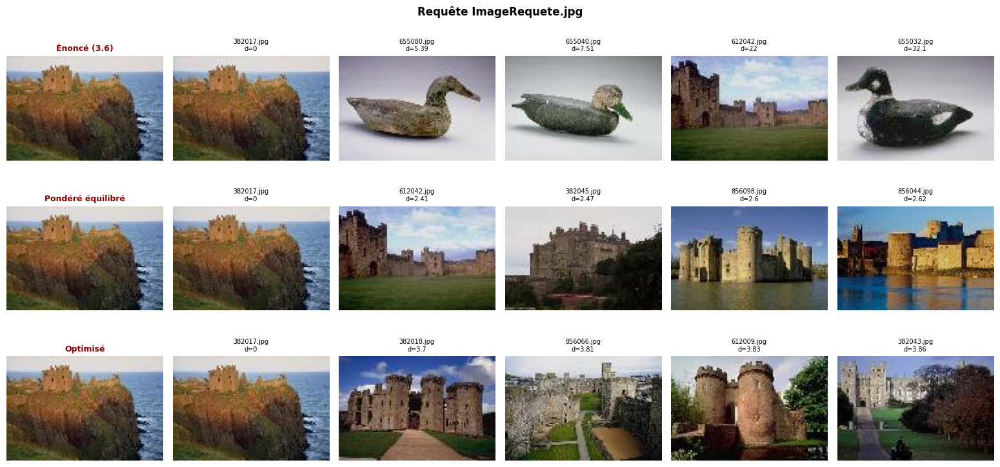

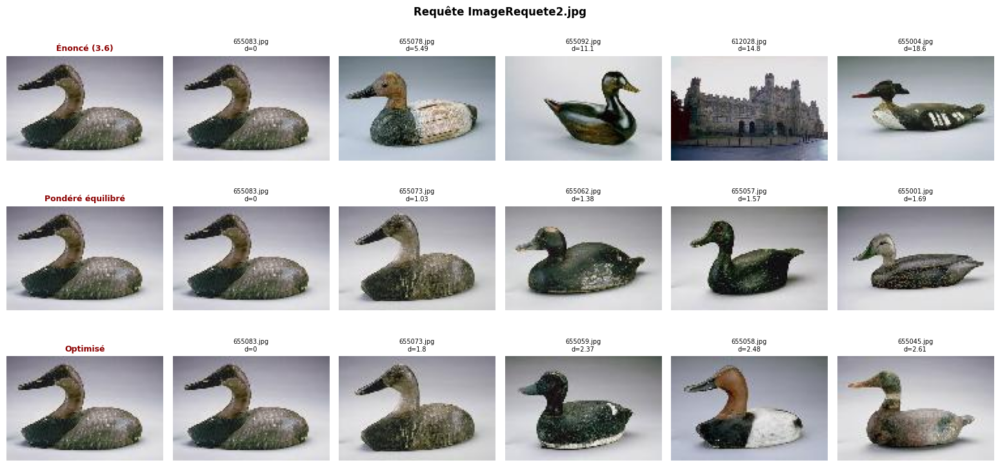

In [27]:
# Recherche automatique de bons poids (petite grille) sur la combinaison améliorée
if LABELS is not None:
    import itertools
    meilleurs = []
    for w in itertools.product([0, 1, 2], repeat=5):
        if sum(w) == 0: continue
        conf = {d: (m, p) for (d, m), p in zip([('histogramme', 'chi2'), ('moments_Lab', E), ('gabor', E),
                                                ('lbp', 'chi2'), ('forme', E)], w) if p > 0}
        meilleurs.append((evaluer(conf, ks=(10,))['mAP'], w))
    meilleurs.sort(reverse=True)
    print('Poids (HSVχ², Lab, Gabor, LBP, HOG) -> mAP')
    for s, w in meilleurs[:5]: print(w, round(s, 3))
    W_OPT = meilleurs[0][1]
    CONF_OPT = {d: (m, p) for (d, m), p in zip([('histogramme', 'chi2'), ('moments_Lab', E), ('gabor', E),
                                                ('lbp', 'chi2'), ('forme', E)], W_OPT) if p > 0}
    for nom_req, img_req in REQUETES.items():
        comparer(img_req, {'Énoncé (3.6)': RES[nom_req]['Coul+Hist+Tex+HOG'],
                           'Pondéré équilibré': RES[nom_req]['Complet pondéré'],
                           'Optimisé': recherche_ponderee(img_req, CONF_OPT)}, nom_req)
else:
    CONF_OPT = {'histogramme': ('chi2', 1), 'moments_Lab': ('euclidienne', 1), 'gabor': ('euclidienne', 1),
                'lbp': ('chi2', 1), 'forme': ('euclidienne', 1)}

### Interprétation — évaluation quantitative

**Référence du hasard :** les classes sont déduites des numéros COREL, ce qui donne 4 catégories : 655 (83 images), 612 (76), 382 (60) et 856 (51). Un système qui tirerait les résultats au hasard obtiendrait une précision d'environ **0,26**. Toutes les méthodes font mieux, sauf les moments de Hu (0,34).

**Pipeline de l'énoncé :**

| Étape | P@5 | mAP |
|---|---|---|
| Image entière | 0,532 | **0,548** |
| Couleur | 0,563 | 0,504 |
| + Histogramme | **0,587** | 0,473 |
| + Texture | 0,415 | 0,403 |
| + HOG | 0,416 | 0,403 |

- L'image entière est étonnamment performante. Comme vu en 3.2, les photos d'une même catégorie COREL sont cadrées de façon très similaire.
- La chute à l'ajout de la texture, puis l'absence d'effet de HOG, confirment le problème d'échelle analysé en 4.1 : les lignes « + Texture », « + HOG » et « GLCM seul » ont des scores identiques.

**Améliorations :**
- La normalisation et la pondération des 4 descripteurs de l'énoncé font passer la mAP de 0,403 à **0,509**.
- La combinaison améliorée (histogramme HSV avec χ², moments Lab, Gabor, LBP avec χ², HOG) atteint **0,554**. Les poids optimisés (2, 1, 0, 2, 2) donnent **0,561**, la meilleure mAP du projet.
- La recherche de poids donne un poids nul à Gabor : son information est redondante avec LBP (texture) et HOG (gradients orientés). Les blocs les plus utiles sont l'histogramme, LBP et HOG.
- Visuellement, la configuration optimisée renvoie 5 châteaux pour la requête 1 et 5 leurres pour la requête 2.

**Pourquoi les scores plafonnent autour de 0,55–0,59 :** sur les images, on voit que **3 des 4 catégories (382, 612, 856) sont des châteaux** et que seule la 655 contient les leurres. Les « deux groupes d'images » de l'énoncé correspondent donc aux châteaux et aux leurres. Une grande partie des « erreurs » comptées ici sont en fait des châteaux retrouvés dans une autre catégorie de châteaux : le résultat est correct pour un utilisateur, mais compté comme faux. Des descripteurs globaux de bas niveau (couleur, texture, gradients) ne peuvent pas distinguer trois séries de photos de châteaux entre elles. Évalués sur les deux groupes (château ou leurre), les scores seraient nettement plus élevés.

**Limites de l'évaluation :** elle porte sur une petite base (270 images), et les poids sont optimisés sur cette même base. Le score de 0,561 est donc légèrement optimiste : il faudrait le valider sur d'autres images.

<h3>4.7 Interface graphique</h3>

Lance la cellule, puis clique sur le lien public (ou utilise l'interface affichée directement sous la cellule). Dépose une image, choisis les descripteurs et la distance, et les résultats s'affichent.

In [28]:
import subprocess, sys
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gradio'], check=True)
    import gradio as gr

    CHOIX = {'Moments couleur RGB': 'couleur', 'Moments Lab': 'moments_Lab', 'Histogramme HSV': 'histogramme',
             'Histogramme Lab': 'hist_Lab', 'Texture GLCM': 'texture', 'Texture Gabor': 'gabor',
             'Texture LBP': 'lbp', 'Forme HOG': 'forme', 'Forme Hu': 'hu'}
    HISTOS = {'histogramme', 'hist_Lab', 'lbp'}

    def interface(img, descripteurs, dist_histo, k):
        if img is None or not descripteurs:
            return []
        conf = {CHOIX[d]: (dist_histo if CHOIX[d] in HISTOS else 'euclidienne', 1) for d in descripteurs}
        res = recherche_ponderee(img, conf)
        return [(IMAGES[n], f'{n}  (d={d:.2f})') for n, d in res[:int(k)]]

    demo = gr.Interface(
        fn=interface,
        inputs=[gr.Image(type='numpy', label='Image requête'),
                gr.CheckboxGroup(list(CHOIX), value=['Histogramme HSV', 'Moments Lab', 'Texture Gabor', 'Texture LBP', 'Forme HOG'],
                                 label='Descripteurs'),
                gr.Dropdown(['chi2', 'intersection', 'bhattacharyya', 'euclidienne'], value='chi2',
                            label='Distance pour les histogrammes'),
                gr.Slider(1, 20, value=10, step=1, label='Nombre de résultats')],
        outputs=gr.Gallery(label='Images les plus similaires', columns=5, height='auto'),
        title='Moteur de recherche d\'images par le contenu (CBIR)',
        description='Descripteurs globaux : couleur, histogramme, texture, forme. Les distances de chaque descripteur sont normalisées puis additionnées.',
        examples=[[im, ['Histogramme HSV', 'Moments Lab', 'Texture Gabor', 'Texture LBP', 'Forme HOG'], 'chi2', 10]
                  for im in REQUETES.values()],
    )
    demo.launch(share=True, debug=False)
else:
    print('Interface Gradio : à lancer dans Colab.')

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e0167b8bfa9f57723f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


<h2>5 Conclusion</h2>

Ce projet a permis de construire un moteur de recherche d'images par le contenu complet : indexation hors ligne d'une base de 270 images COREL, puis recherche en ligne par similarité de descripteurs globaux.

**Principaux enseignements :**

1. **Chaque descripteur capte un aspect différent de l'image.**
   - La couleur (moments, histogramme) décrit l'ambiance globale. Elle est compacte, robuste aux rotations et au miroir, mais ignore la forme.
   - La texture (GLCM, Gabor, LBP) décrit les motifs locaux.
   - HOG décrit la silhouette et l'orientation des contours. Il est très efficace pour les leurres photographiés sur fond uniforme, mais n'est pas invariant à la rotation.
2. **La façon de combiner les descripteurs compte autant que le choix des descripteurs.** La concaténation brute de l'énoncé fait dominer le contraste GLCM (100 % de la distance), ce qui dégrade les résultats (mAP 0,403) et rend l'ajout de HOG inutile. Normaliser chaque distance par bloc puis pondérer fait remonter la mAP à 0,509 avec les mêmes descripteurs.
3. **Les choix adaptés donnent les meilleurs résultats :** la distance χ² pour les histogrammes, l'espace Lab ou HSV pour la couleur, LBP plutôt que GLCM pour la texture. La meilleure combinaison (histogramme HSV, moments Lab, LBP et HOG, pondérés) atteint une mAP de 0,561, contre 0,403 pour le pipeline de l'énoncé.
4. **La robustesse dépend de la transformation.** Les descripteurs statistiques sont invariants aux permutations de pixels (rotation de 90°, miroir) et au changement d'échelle, HOG ne l'est pas. La translation et les petites rotations dégradent surtout HOG et la texture. L'histogramme HSV reste le plus stable, à condition de compléter les bords en miroir et non en noir, car des pixels noirs ajoutés faussent la couleur. Enfin, quand une catégorie contient des images très proches entre elles (les leurres), le classement change facilement alors que les résultats restent pertinents.
5. **Les descripteurs globaux de bas niveau ont une limite.** Ils séparent bien les leurres des châteaux, mais ne distinguent pas les trois catégories de châteaux entre elles, car cette distinction est sémantique et non visuelle.

**Perspectives :**
- Des descripteurs locaux (SIFT, ORB) avec un sac de mots visuels, pour être robuste au cadrage et aux transformations.
- Des descripteurs appris par des réseaux de neurones convolutifs pré-entraînés, qui capturent des notions de plus haut niveau.
- La segmentation de l'objet avant de calculer les descripteurs de forme.

Une interface graphique (section 4.7) permet de soumettre une image requête, de choisir les descripteurs et la distance, et d'afficher les résultats.